# Лабораторная работа №3. Транскрипция (G2P)

**Курс «Синтез речи», Университет ИТМО**

Отчёт по разработке модуля преобразования графем в фонемы для русского языка на корпусе RUSLAN: подготовка фонетических данных, анализ инвентаря, модуль `G2P`, метаданные для акустической модели.

**Критерии приёмки (из README):**

| Критерий | Порог |
|---|---|
| PER на связном тексте, `test` | ≤ 0,025 |
| PER на остатке (слов нет ни в одном словаре), `test` | ≤ 0,20 |
| Все фонемы в `metadata_phones.csv` принадлежат `common/phones_mfa.txt` | обязательно |
| Произношения остатка получены своей моделью, а не готовым транскриптором | обязательно |

**Как устроен отчёт.** Разделы идут по пунктам задания: 1 - данные, 2 - разведочный анализ, 3 - модуль транскрипции, 4 - метаданные для лабораторной №4, затем дополнительные задания. Код модуля - в `g2p.py`, подготовка данных - в `prepare_lexicon.py`; в отчёте они импортируются, а не копируются.

In [ ]:
import contextlib
import csv
import glob
import io
import os
import pickle
import random
import re
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import g2p as G
import prepare_lexicon as PL

SIL = "<SIL>"
VOWELS = set("a e i o u æ ɐ ə ɛ ɨ ɪ ɵ ʉ ʊ".split())
TARGET = Path("../../common/phones_mfa.txt").read_text(encoding="utf-8").split()

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.family": "DejaVu Sans"})
BLUE, ORANGE, GREEN, RED, GRAY = "#4E89EA", "#F4752C", "#31F45F", "#D0191F", "#8C8C8C"

def read_table(path):
    return pd.read_csv(path, sep="|", quoting=csv.QUOTE_NONE, keep_default_na=False)

## 1. Данные и подготовка фонетической разметки

Источники:

1. `data/RUSLAN_align_v2/*.TextGrid` - выравнивание MFA (Montreal Forced Aligner, русская модель v3.1.0). В каждом файле два яруса: `words` (слова и интервалы тишины с пустой меткой) и `phones` (фонемы с длительностями). Слова с фонемами сопоставляются по **середине интервала фонемы**: границы ярусов пишутся независимо и могут расходиться в последнем знаке.
2. `data/metadata_RUSLAN_22200_normalized.csv` - результат лабораторной №1. Выравнивание построено по **сырому** тексту, поэтому в нём есть фразы, которые нормализатор отбросил (аббревиатуры, числа, скобки); оставляем только 21 854 фразы из метаданных лабы 1.
3. `data/mfa/root/pretrained_models/dictionary/russian_mfa.dict` - оригинальный словарь MFA (v3.1.0); копируется в `data/russian_mfa.dict`.

Скрипт `prepare_lexicon.py` (пример из задания) доработан:

- пути приведены к локальным (`RUSLAN_align_v2`; в исходнике стоял каталог `RUSLAN_22050_align_v2`, которого у нас нет);
- убрана отладочная печать списка всех 22 тыс. файлов; разметка читается за один проход (раньше - дважды);
- **фразы с `spn` отбрасываются целиком** (требование README) во всех таблицах; в исходнике они оставались в `tokens_phones.csv`, а токены `spn` вычищал только `g2p.load_tokens`;
- у паузы в `tokens_phones_sil.csv` токен стал `<SIL>` (раньше - пустая строка, которую `pandas` читает как `NaN`);
- копируется оригинальный `russian_mfa.dict`; опциональные аргументы командной строки позволяют собрать те же файлы из другой разметки (ниже - из перезапуска MFA, выполненного в лабе 2).

Фонемы приводятся к целевому алфавиту: NFC-нормализация и удаление знака долготы `ː` (в `common/phones_mfa.txt` долгих фонем нет; обоснование - в разделе 2.6). Пустая метка фонемного яруса - пауза `<SIL>`.

In [2]:
tokens = read_table("data/tokens_phones.csv")
tokens_sil = read_table("data/tokens_phones_sil.csv")
lexicon_df = read_table("data/lexicon.csv")
mfa = G.load_mfa_dict()

files = pd.DataFrame([
    ("tokens_phones.csv", len(tokens), "id | token_id | token | phones | set", "обучение транскриптора, без пауз"),
    ("tokens_phones_sil.csv", len(tokens_sil), "то же, плюс строки <SIL>", "обучение акустической модели (лаба 4)"),
    ("lexicon.csv", len(lexicon_df), "word | phones | count", "словарь произношений по train"),
    ("russian_mfa.dict", sum(len(v) for v in mfa.values()), "word [p ...] phones", "оригинальный словарь MFA (после схлопывания ː)"),
], columns=["файл", "строк", "поля", "назначение"])
display(files)

n_utt = tokens.id.nunique()
print(f"Фраз: {n_utt} (train {tokens[tokens.set == 'train'].id.nunique()}, test {tokens[tokens.set == 'test'].id.nunique()})")
print(f"Токенов: {len(tokens)} (train {(tokens.set == 'train').sum()}, test {(tokens.set == 'test').sum()})")
print(f"Пауз <SIL> в tokens_phones_sil.csv: {(tokens_sil.token == SIL).sum()}")
print(f"Типов слов в train: {tokens[tokens.set == 'train'].token.nunique()}, в test: {tokens[tokens.set == 'test'].token.nunique()}")
print(f"Слов в оригинальном словаре MFA: {len(mfa)}, из них с несколькими произношениями: {sum(len(v) > 1 for v in mfa.values())}")
tokens.head(8)

,файл,строк,поля,назначение
0,tokens_phones.csv,219358,id | token_id | token | phones | set,"обучение транскриптора, без пауз"
1,tokens_phones_sil.csv,271781,"то же, плюс строки <SIL>",обучение акустической модели (лаба 4)
2,lexicon.csv,39156,word | phones | count,словарь произношений по train
3,russian_mfa.dict,470097,word [p ...] phones,оригинальный словарь MFA (после схлопывания ː)


Фраз: 19600 (train 15647, test 3953)
Токенов: 219358 (train 175171, test 44187)
Пауз <SIL> в tokens_phones_sil.csv: 52423
Типов слов в train: 38514, в test: 15880
Слов в оригинальном словаре MFA: 452397, из них с несколькими произношениями: 17094


,id,token_id,token,phones,set
0,000000_RUSLAN,0,с,s̪,test
1,000000_RUSLAN,1,тревожным,t̪ rʲ ɪ v o ʐ n̪ ɨ m,test
2,000000_RUSLAN,2,чувством,tɕ u s̪ t̪ v ə m,test
3,000000_RUSLAN,3,берусь,bʲ ɪ r u sʲ,test
4,000000_RUSLAN,4,я,j a,test
5,000000_RUSLAN,5,за,z̪ ə,test
6,000000_RUSLAN,6,перо,pʲ ɪ r o,test
7,000001_RUSLAN,0,кого,k ɐ v o,train


In [ ]:
# Слова с несколькими произношениями в словаре, который собирается по train
train = tokens[tokens.set == "train"]
lex = G.build_lexicon(train)
lex_rows = lexicon_df.copy()
lex_rows["count"] = lex_rows["count"].astype(int)
print(f"lexicon.csv: {lex_rows.word.nunique()} слов, {len(lex_rows)} пар «слово - произношение»")
print(f"Слов с несколькими произношениями: {(lex_rows.groupby('word').size() > 1).sum()}")
lex_rows.sort_values("count", ascending=False).head(8)

lexicon.csv: 38514 слов, 39156 пар «слово - произношение»
Слов с несколькими произношениями: 607


,word,phones,count
10735,и,i,5111
38985,я,j a,3520
17749,не,ɲ i,2778
2684,в,v,2566
2685,в,f,1796
37743,что,ʂ t̪ o,1626
16861,на,n̪ ə,1517
29396,с,s̪,1428


### 1.1. Две разметки: официальная v2 и перезапуск v3

В лабораторной №2 (дополнительное задание) корпус был выровнен заново по нормализованному тексту (`data/mfa/align_v3/`, словарь расширен произношениями OOV-слов). Для лабораторной №3 основной остаётся **официальная v2** - так сказано в задании, и пороги приёмки рассчитаны на неё. Но v3 может оказаться лучше как источник данных для лабораторной №4, поэтому те же файлы собраны и для неё (`data/v3/`), а ключевые результаты ниже продублированы на v3.

In [ ]:
kept_ids = PL.read_kept_ids(PL.NORMALIZED_META)
variants = [("v2 (официальная)", PL.ALIGN_DIR, ""), ("v3 (перезапуск, лаба 2)", "../../data/mfa/align_v3/", "v3")]
rows, dropped_v2 = [], None
for name, align_dir, subdir in variants:
    aligned = {Path(p).stem for p in glob.glob(os.path.join(align_dir, "*.TextGrid"))} & kept_ids
    tab = read_table(os.path.join("data", subdir, "tokens_phones.csv"))
    dropped = aligned - set(tab.id)
    if subdir == "":
        dropped_v2 = dropped
    rows.append({
        "разметка": name,
        "фраз выровнено (после лабы 1)": len(aligned),
        "отброшено из-за spn": len(dropped),
        "фраз в таблице": tab.id.nunique(),
        "токенов": len(tab),
        "типов слов": tab.token.nunique(),
        "токенов с дефисом": int(tab.token.str.contains("[-‐]").sum()),
    })
pd.DataFrame(rows).set_index("разметка").T

разметка,v2 (официальная),"v3 (перезапуск, лаба 2)"
фраз выровнено (после лабы 1),21853,21854
отброшено из-за spn,2253,14
фраз в таблице,19600,21840
токенов,219358,254865
типов слов,43880,47597
токенов с дефисом,0,2


In [ ]:
# Почему в v2 отброшено 10 % фраз: что именно размечено как spn
with contextlib.redirect_stderr(io.StringIO()):
    dropped_rows = PL.read_alignment(PL.ALIGN_DIR, dropped_v2)
spn_tokens = Counter(r["token"] for r in dropped_rows if "spn" in r["phones"].split())

def spn_reason(token):
    if token == "[bracketed]":
        return "[bracketed] (скобки в исходном тексте)"
    if re.search("[-‐]", token):
        return "слово с дефисом (что-то, как-то, из-за)"
    return "другое"

reasons = Counter()
for token, n in spn_tokens.items():
    reasons[spn_reason(token)] += n
print("токенов spn в отброшенных фразах:", sum(spn_tokens.values()))
print(pd.Series(reasons, name="токенов").sort_values(ascending=False).to_string())
print("\nсамые частые spn-токены:", spn_tokens.most_common(12))
other = [t for t in spn_tokens if spn_reason(t) == "другое"]
print("другое, примеры:", other[:25])

токенов spn в отброшенных фразах: 2491
слово с дефисом (что-то, как-то, из-за)    2163
[bracketed] (скобки в исходном тексте)      266
другое                                       62

самые частые spn-токены: [('[bracketed]', 266), ('что‐то', 226), ('как‐то', 126), ('какие‐то', 98), ('все‐таки', 82), ('кто‐то', 78), ('какой‐то', 65), ('из‐за', 44), ('что‐нибудь', 40), ('когда‐то', 39), ('нью‐йорке', 31), ('какая‐то', 30)]
другое, примеры: ['ленински', '/библиография', 'джасис', 'застежку', 'супрематиста', 'исправительно', 'хиллс', 'мидоу', 'йоркское', 'неисчерпаемая', 'милицейского', '/например', 'дзэн', 'советско', '(', 'простодушие)', '(тогда', ')', '(у', "о'кей", '(в', "о'коннор", '(кстати', '(она', 'летосчисление']


**Наблюдения.**

- В v2 **10,3 % фраз (2253) содержат `spn`** и из-за требования README удаляются целиком. Почти все они - из-за двух причин: слов с дефисом (`что‐то`, `как‐то`, `из‐за` - словаря MFA для них нет, а токенизация по пробелу не разрезает дефис) и скобок (`[bracketed]`). В v3 дефисные слова разрезаны на два токена (так же делает токенизатор из лабы 2), поэтому потеряны всего 14 фраз.
- Побочный эффект v2, важный для G2P: в данных **нет ни одного слова с дефисом**, хотя в живом тексте они часты. В обработке слова с дефисом надо уметь, но проверить на разметке v2 это нельзя; на v3 - можно (там дефис разрезан, остаются только `о'кей`, `э-э`).
- Отброшенные фразы случайны относительно разбиения `train`/`test` (id делится на 5 - не связано с содержанием), поэтому смещения в метриках это не создаёт, а теряется ~10 % данных.

## 2. Разведочный анализ фонемного инвентаря

### 2.1. Какие фонемы есть в корпусе: соответствие IPA, длительность и её разброс

Длительности фонем берутся из исходных `TextGrid` (ярус `phones`); интервалы читаются один раз и кэшируются в `data/cache_phone_intervals_v2.pkl`. Длительности лежат на сетке 10 мс (как и в лабе 2) - это ограничение разметки MFA.

In [ ]:
CACHE = "data/cache_phone_intervals_v2.pkl"

def read_phone_intervals(align_dir=PL.ALIGN_DIR):
    from praatio import textgrid
    recs = []
    for path in sorted(glob.glob(os.path.join(align_dir, "*.TextGrid"))):
        uid = Path(path).stem
        _, phone_tier = textgrid.openTextgrid(path, True).tiers
        for k, e in enumerate(phone_tier.entries):
            recs.append((uid, k, unicodedata.normalize("NFC", e.label), round(e.end - e.start, 4)))
    return pd.DataFrame(recs, columns=["id", "k", "phone_raw", "dur"])

if Path(CACHE).exists():
    iv = pd.read_pickle(CACHE)
else:
    iv = read_phone_intervals()
    iv.to_pickle(CACHE)

iv = iv[iv.id.isin(set(tokens.id))].copy()                      # только фразы, попавшие в обучающую таблицу
iv["long"] = iv.phone_raw.str.endswith("ː")
iv["phone"] = iv.phone_raw.str.replace("ː", "", regex=False).replace("", SIL)
print(f"Интервалов фонемного яруса: {len(iv)}; разных меток (сырых): {iv.phone_raw.nunique()}; после схлопывания ː: {iv.phone.nunique()}")

Интервалов фонемного яруса: 1289331; разных меток (сырых): 88; после схлопывания ː: 56


In [ ]:
# Классы и фонетические описания (Help:IPA/Russian). Ключи - символы из common/phones_mfa.txt.
PHONE_INFO = {
    # гласные
    "a": ("гласная", "а, я", "[a] ударная, в том числе между мягкими: «мать»"),
    "æ": ("гласная", "я, а", "[æ] ударная между мягкими согласными: «пять»"),
    "e": ("гласная", "е, э", "[e] ударная после мягкой согласной"),
    "ɛ": ("гласная", "э, е", "[ɛ] ударная «э» и «е» после твёрдой: «это», «жест»"),
    "i": ("гласная", "и", "[i] ударная и частично безударная"),
    "ɨ": ("гласная", "ы", "[ɨ] «ы»; в безударной позиции символ тот же"),
    "o": ("гласная", "о", "[o] ударная после твёрдой"),
    "ɵ": ("гласная", "ё, о", "[ɵ] ударная «ё» и «о» после мягкой"),
    "u": ("гласная", "у", "[u] ударная после твёрдой"),
    "ʉ": ("гласная", "ю, у", "[ʉ] ударная «ю» и «у» после мягкой"),
    "ɐ": ("гласная", "а, о", "[ɐ] безударная, 1-й предударный слог и конец слова"),
    "ə": ("гласная", "а, о, е", "[ə] безударная, остальные позиции"),
    "ɪ": ("гласная", "и, е, я", "[ɪ] безударная после мягкой согласной"),
    "ʊ": ("гласная", "у, ю", "[ʊ] безударная"),
    # согласные
    "p": ("согласная", "п", "глухой губной взрывной"),
    "pʲ": ("согласная", "пь", "то же, мягкий"),
    "b": ("согласная", "б", "звонкий губной взрывной"),
    "bʲ": ("согласная", "бь", "то же, мягкий"),
    "t̪": ("согласная", "т", "глухой зубной взрывной"),
    "tʲ": ("согласная", "ть", "то же, мягкий"),
    "d̪": ("согласная", "д", "звонкий зубной взрывной"),
    "dʲ": ("согласная", "дь", "то же, мягкий"),
    "k": ("согласная", "к", "глухой задненёбный взрывной"),
    "c": ("согласная", "к перед мягкими", "палатальный [c] ≈ [kʲ]"),
    "ɡ": ("согласная", "г", "звонкий задненёбный взрывной"),
    "ɟ": ("согласная", "г перед мягкими", "палатальный [ɟ] ≈ [ɡʲ]"),
    "x": ("согласная", "х", "глухой велярный щелевой"),
    "ç": ("согласная", "хь", "мягкий [xʲ], палатальный щелевой"),
    "ɣ": ("согласная", "г (фрик.)", "звонкий велярный щелевой: «бог», «господи»"),
    "f": ("согласная", "ф, в", "глухой губно-зубной щелевой"),
    "fʲ": ("согласная", "фь, вь", "то же, мягкий"),
    "v": ("согласная", "в", "звонкий губно-зубной щелевой"),
    "vʲ": ("согласная", "вь", "то же, мягкий"),
    "s̪": ("согласная", "с", "глухой зубной щелевой"),
    "sʲ": ("согласная", "сь", "то же, мягкий"),
    "z̪": ("согласная", "з", "звонкий зубной щелевой"),
    "zʲ": ("согласная", "зь", "то же, мягкий"),
    "ʂ": ("согласная", "ш", "глухой ретрофлексный щелевой"),
    "ʐ": ("согласная", "ж", "звонкий ретрофлексный щелевой"),
    "ɕ": ("согласная", "щ, сч", "мягкий глухой щелевой [ɕː]"),
    "ʑ": ("согласная", "зж, жж, ждь", "мягкий звонкий щелевой [ʑː]: «дрожжи», «дождь»"),
    "t̪s̪": ("согласная", "ц", "глухая аффриката"),
    "tɕ": ("согласная", "ч", "мягкая глухая аффриката"),
    "tʂ": ("согласная", "тш, дш", "твёрдая глухая аффриката (на стыке морфем)"),
    "dʐ": ("согласная", "дж, жж", "звонкая твёрдая аффриката: «джаз»"),
    "d̪z̪": ("согласная", "дз", "звонкая аффриката: «дзен»"),
    "m": ("согласная", "м", "губной носовой"),
    "mʲ": ("согласная", "мь", "то же, мягкий"),
    "n̪": ("согласная", "н", "зубной носовой"),
    "ɲ": ("согласная", "нь", "мягкий носовой (палатальный)"),
    "ɫ": ("согласная", "л", "твёрдый («тёмный») боковой"),
    "ʎ": ("согласная", "ль", "мягкий боковой (палатальный)"),
    "r": ("согласная", "р", "твёрдый дрожащий"),
    "rʲ": ("согласная", "рь", "то же, мягкий"),
    "j": ("согласная", "й, я/е/ё/ю после гласной", "палатальный глайд"),
}
missing = set(TARGET) - set(PHONE_INFO) - {SIL}
print("целевых фонем без описания:", missing or "нет", "| лишних:", set(PHONE_INFO) - set(TARGET) or "нет")

word_freq = Counter(tokens.token)
phone_words = defaultdict(Counter)
for tok, ph in zip(tokens.token, tokens.phones):
    for p in set(ph.split()):
        phone_words[p][tok] += 1

def examples(p, k=3):
    words = [(w, n) for w, n in phone_words[p].most_common(60) if len(w) >= 3][:k]
    return ", ".join(w for w, _ in words)

dur_ms = iv[iv.phone != SIL].assign(ms=lambda d: d.dur * 1000)
stats = dur_ms.groupby("phone").ms.agg(n="size", mean="mean", std="std", p5=lambda s: s.quantile(.05), p95=lambda s: s.quantile(.95))
stats["cv"] = stats["std"] / stats["mean"]
stats["share_%"] = stats.n / stats.n.sum() * 100
table = stats.reindex(TARGET[1:]).copy()
table.insert(0, "класс", [PHONE_INFO[p][0] for p in table.index])
table.insert(1, "буквы", [PHONE_INFO[p][1] for p in table.index])
table["примеры"] = [examples(p) for p in table.index]
table = table.rename(columns={"n": "N", "mean": "ср., мс", "std": "σ, мс", "cv": "σ/ср.", "p5": "P5", "p95": "P95"})
table = table.sort_values(["класс", "N"], ascending=[True, False])
table[["класс", "буквы", "N", "share_%", "ср., мс", "σ, мс", "σ/ср.", "P5", "P95", "примеры"]].round(2)

целевых фонем без описания: нет | лишних: нет


,класс,буквы,N,share_%,"ср., мс","σ, мс",σ/ср.,P5,P95,примеры
phone,,,,,,,,,,
ɪ,гласная,"и, е, я",100236,8.10,17.72,25.55,1.44,10.0,70.00,"его, меня, еще"
ə,гласная,"а, о, е",93742,7.58,39.72,34.42,0.87,10.0,110.00,"это, было, что"
ɐ,гласная,"а, о",65308,5.28,64.15,20.95,0.33,30.0,100.00,"сказал, она, затем"
a,гласная,"а, я",55277,4.47,88.91,35.66,0.40,40.0,140.00,"как, меня, так"
e,гласная,"е, э",43311,3.50,73.68,34.96,0.47,30.0,130.00,"мне, есть, еще"
ɨ,гласная,ы,37905,3.06,52.03,35.70,0.69,10.0,110.00,"был, было, даже"
o,гласная,о,36997,2.99,84.48,36.61,0.43,40.0,140.00,"что, его, вот"
i,гласная,и,36878,2.98,70.39,40.46,0.57,30.0,150.00,"они, или, говорит"
ʊ,гласная,"у, ю",25197,2.04,59.91,35.36,0.59,30.0,130.00,"думаю, маруся, знаю"


Паузы (пустая метка фонемного яруса): 52423 шт., среднее 129 мс, медиана 60 мс


,count,mean,std,min,25%,50%,75%,max
класс,,,,,,,,
гласные,524984.0,56.0,40.7,4.9,30.0,50.0,80.0,730.0
согласные,711924.0,84.9,36.7,5.0,60.0,80.0,110.0,540.0


Доля фонем длительностью ровно 10 мс: гласные 22.9%, согласные 0.2%
Редуцированные гласные (ɐ ə ɪ ʊ): среднее 39 мс, 10 мс - 40.1%
Нередуцированные (a e i o u ɛ æ ɵ ʉ): среднее 80 мс, 10 мс - 0.6%


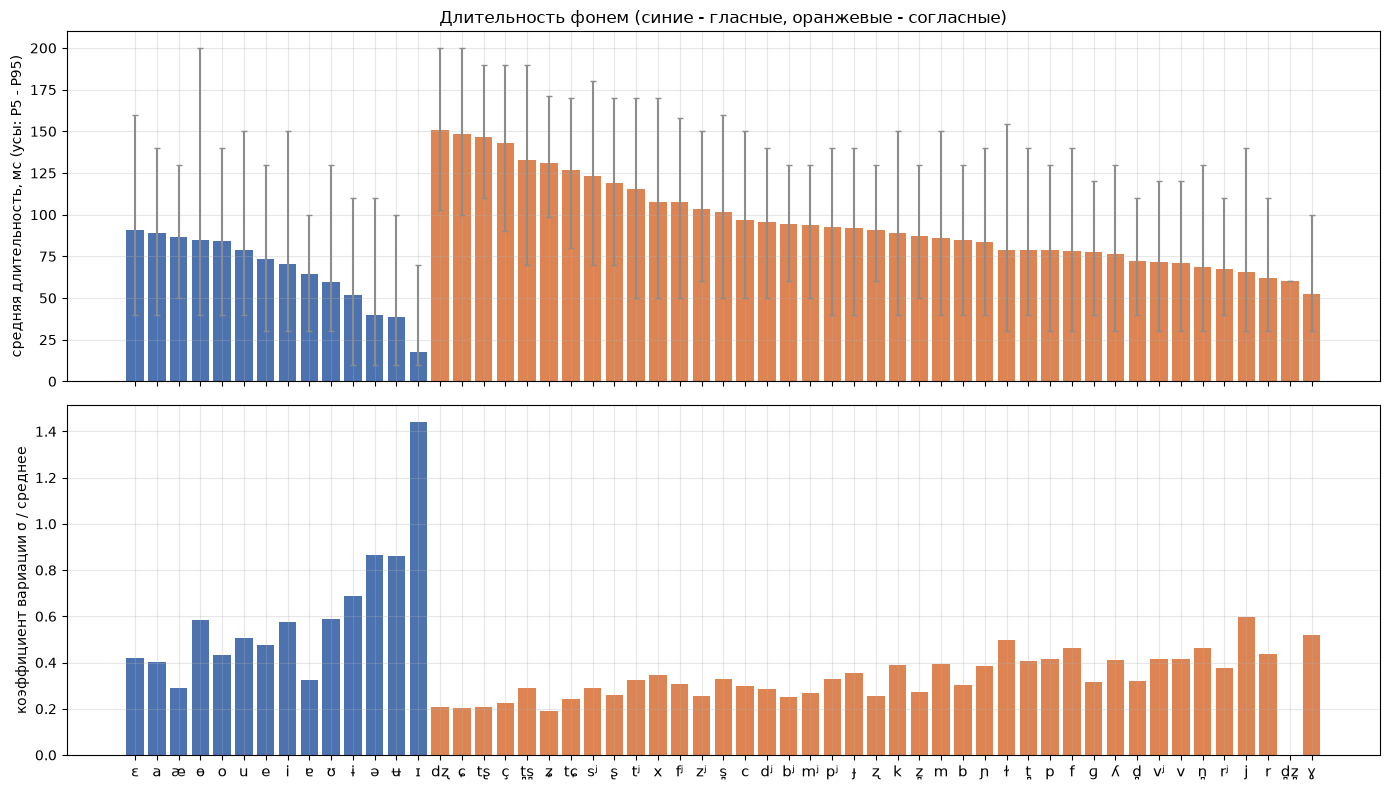

In [ ]:
sil = iv[iv.phone == SIL].dur * 1000
print(f"Паузы (пустая метка фонемного яруса): {len(sil)} шт., среднее {sil.mean():.0f} мс, медиана {sil.median():.0f} мс")

summary = dur_ms.assign(класс=lambda d: np.where(d.phone.isin(VOWELS), "гласные", "согласные")).groupby("класс").ms.describe()
display(summary.round(1))

ten = (dur_ms.ms.round() == 10)
print(f"Доля фонем длительностью ровно 10 мс: гласные {ten[dur_ms.phone.isin(VOWELS)].mean():.1%}, согласные {ten[~dur_ms.phone.isin(VOWELS)].mean():.1%}")
red = dur_ms[dur_ms.phone.isin(["ɐ", "ə", "ɪ", "ʊ"])]
full = dur_ms[dur_ms.phone.isin(["a", "e", "i", "o", "u", "ɛ", "æ", "ɵ", "ʉ"])]
print(f"Редуцированные гласные (ɐ ə ɪ ʊ): среднее {red.ms.mean():.0f} мс, 10 мс - {(red.ms.round() == 10).mean():.1%}")
print(f"Нередуцированные (a e i o u ɛ æ ɵ ʉ): среднее {full.ms.mean():.0f} мс, 10 мс - {(full.ms.round() == 10).mean():.1%}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
order = table.sort_values(["класс", "ср., мс"], ascending=[True, False]).index.tolist()
colors = [BLUE if p in VOWELS else ORANGE for p in order]
means = table.loc[order, "ср., мс"]
lo, hi = means - table.loc[order, "P5"], table.loc[order, "P95"] - means
axes[0].bar(range(len(order)), means, yerr=[lo, hi], color=colors, capsize=2, ecolor=GRAY)
axes[0].set_ylabel("средняя длительность, мс (усы: P5 - P95)")
axes[0].set_title("Длительность фонем (синие - гласные, оранжевые - согласные)")
axes[1].bar(range(len(order)), table.loc[order, "σ/ср."], color=colors)
axes[1].set_ylabel("коэффициент вариации σ / среднее")
axes[1].set_xticks(range(len(order)))
axes[1].set_xticklabels(order, fontsize=11)
plt.tight_layout()
plt.show()

**Наблюдения.**

- В корпусе встречаются **все 55 фонем целевого алфавита** (плюс `<SIL>`), других нет - после схлопывания знака долготы (раздел 2.6) инвентарь совпадает с `common/phones_mfa.txt` один в один. Это **14 гласных и 41 согласная**: и по составу, и по описанию соответствует IPA для русского языка с поправками MFA: зубные символы `t̪ d̪ s̪ z̪ n̪` и тёмное `ɫ` для твёрдых, палатальные `c ɟ ç ɲ ʎ` для мягких заднеязычных, носового и бокового, аффрикаты `t̪s̪ tɕ tʂ dʐ d̪z̪` одним символом.
- **Гласные.** Различие «ударный/безударный» закодировано качеством гласной: нередуцированные `a e i o u ɛ æ ɵ ʉ` и редуцированные `ɐ ə ɪ ʊ`. Отдельного знака ударения нет, это тема дополнительных заданий.
- **Длительность.** Гласные короче согласных, а значительная доля фонем сидит на минимуме разметки (10 мс) - особенно редуцированные гласные. Для акустической модели это шум: «длительность» редуцированной гласной по этой разметке - почти всегда нижняя граница сетки.
- **Вариативность.** Коэффициент вариации у большинства фонем 0,4–0,6: гласные и сонорные «растягиваются» сильнее; взрывные и аффрикаты стабильнее. Фонемы с аномально высоким разбросом - как правило, редкие, и их статистика ненадёжна.
- Реально предсказывать длительность придётся акустической модели; для G2P важно лишь, чтобы на вход шла последовательность, различающая ударные/безударные гласные, твёрдые/мягкие согласные.

### 2.2. Самые редкие фонемы

,N,на 10⁶ фонем,типов слов,фраз,в test,примеры слов
d̪z̪,1,0.8,1,1,0,зальцбурге (1)
ʑ,18,14.6,13,18,5,"уезжал (3), приезжал (3), зажженными (2), заезженную (1)"
ɣ,23,18.6,10,23,4,"ого (5), бухгалтер (4), сверхсрочников (4), сверхсрочники (4)"
dʐ,227,183.5,106,218,59,"пиджак (18), джинсы (12), джинсах (9), пиджаке (9)"
tʂ,280,226.4,59,271,49,"лучше (109), лучшие (28), лучших (14), лучший (12)"
ç,496,401.0,237,481,86,"стихи (62), хиггинс (17), эпохи (14), слухи (11)"
ɵ,950,768.0,100,909,177,"все (695), майор (34), районе (26), ньюйоркер (13)"
fʲ,1865,1507.8,671,1702,372,"любовь (60), кофе (57), фима (48), шофер (36)"
ʉ,2390,1932.2,837,2175,474,"люди (193), чуть (108), людей (58), союзе (44)"
æ,3413,2759.3,1369,3079,674,"дядя (102), пять (68), опять (54), отвечает (38)"


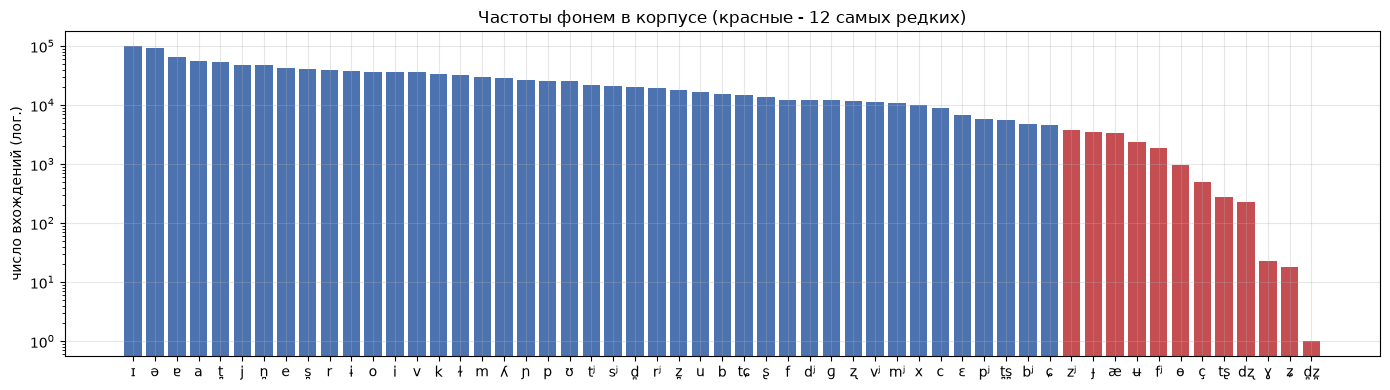

In [ ]:
counts = Counter(p for s in tokens.phones for p in s.split())
freq = pd.Series(counts).reindex(TARGET[1:]).fillna(0).astype(int).sort_values()
rare = freq.head(12)
by_phone_types = {p: len(phone_words[p]) for p in rare.index}
utt_with = {p: tokens[tokens.phones.str.split().map(lambda s: p in s)].id.nunique() for p in rare.index}
test_cnt = Counter(p for s in tokens[tokens.set == "test"].phones for p in s.split())
rare_df = pd.DataFrame({
    "N": rare, "на 10⁶ фонем": (rare / freq.sum() * 1e6).round(1), "типов слов": pd.Series(by_phone_types),
    "фраз": pd.Series(utt_with), "в test": pd.Series({p: test_cnt[p] for p in rare.index}),
    "примеры слов": pd.Series({p: ", ".join(f"{w} ({n})" for w, n in phone_words[p].most_common(4)) for p in rare.index}),
})
display(rare_df)

fig, ax = plt.subplots(figsize=(14, 4))
vals = freq.sort_values(ascending=False)
ax.bar(range(len(vals)), vals.values, color=[RED if p in rare.index else BLUE for p in vals.index])
ax.set_yscale("log")
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(vals.index, fontsize=10)
ax.set_ylabel("число вхождений (лог.)")
ax.set_title("Частоты фонем в корпусе (красные - 12 самых редких)")
plt.tight_layout()
plt.show()

In [10]:
# Откуда берутся самые редкие фонемы: все слова и контексты для трёх самых редких
for p in rare.index[:4]:
    ws = [(w, n) for w, n in phone_words[p].most_common(30)]
    print(f"{p}: {sum(n for _, n in ws)} токенов, слова: {ws[:15]}")
    print("   произношения:", [tokens[tokens.token == w].phones.iloc[0] for w, _ in ws[:4]])

d̪z̪: 1 токенов, слова: [('зальцбурге', 1)]
   произношения: ['z̪ ɐ ʎ d̪z̪ b ʊ r ɟ e']
ʑ: 18 токенов, слова: [('уезжал', 3), ('приезжал', 3), ('зажженными', 2), ('заезженную', 1), ('обожженный', 1), ('прожженным', 1), ('выезжавший', 1), ('зажженной', 1), ('заезжала', 1), ('съезжу', 1), ('езжу', 1), ('дребезжал', 1), ('дождевых', 1)]
   произношения: ['ʊ j ɪ ʑ a ɫ', 'p rʲ ɪ j ɪ ʑ a ɫ', 'z̪ ɐ ʑ ɪ n̪ ɨ mʲ ɪ', 'z̪ ɐ j e ʑ ɪ n̪ ʊ j ʊ']
ɣ: 23 токенов, слова: [('ого', 5), ('бухгалтер', 4), ('сверхсрочников', 4), ('сверхсрочники', 4), ('бухгалтеров', 1), ('сверхсрочнику', 1), ('сверхсрочник', 1), ('сверхсрочника', 1), ('бухгалтерию', 1), ('бухгалтера', 1)]
   произношения: ['o ɣ o', 'b ʊ ɣ a ɫ tʲ ɪ r', 's̪ vʲ e r ɣ s̪ r o tɕ ɲ ɪ k ə f', 's̪ vʲ e r ɣ s̪ r o tɕ ɲ ɪ c ɪ']
dʐ: 136 токенов, слова: [('пиджак', 18), ('джинсы', 12), ('джинсах', 9), ('пиджаке', 9), ('джон', 8), ('джина', 7), ('джин', 6), ('поджидали', 5), ('джаз', 4), ('джемпер', 4), ('джаза', 4), ('пиджаки', 4), ('джинсами', 3), ('джу

**Наблюдения и что с этим делать.**

- Распределение частот - почти «хвост» из степенного закона: самые частые фонемы (`ɪ ə ɐ a`) встречаются 55–100 тыс. раз, а **пять самых редких - менее 300 раз** на 1,24 млн фонем: `d̪z̪` (1 раз, «зальцбург»), `ʑ` (18), `ɣ` (23), `dʐ` (227), `tʂ` (280).
- Это не случайные ошибки разметки, а **позиционные аллофоны и редкие буквосочетания**: `ʑ` - только `зж/жж` в корнях «уезжал», «зажжённый»; `ɣ` - озвончённое `х` в «бухгалтер», «сверхсрочник» и междометие «ого»; `dʐ`, `tʂ` - «дж» (пиджак, джинсы) и «чш» (лучше, лучший); `ç` - `х` перед `и` («стихи», «эпохи»). Все они выводятся из орфографии по правилам, поэтому **G2P может их воспроизвести**, но только если правило прописано явно: общий классификатор их почти не увидит.
- `ɵ` формально редка (950 вхождений), но **73 % из них - одно слово «все»** (вариант «всё»): в тексте корпуса почти нет буквы `ё` (13 вхождений в 22 тыс. фраз), и G2P по написанию не может отличить «все» от «всё», «пришел» от «пришёл». Это отдельная проблема (раздел 2.5 и дополнительные задания).
- **Что с ними можно сделать.** Инвентарь менять нельзя (`common/phones_mfa.txt` фиксирован, все 55 фонем в нём присутствуют), поэтому варианты такие:
  1. оставить как есть: три самые редкие фонемы (`d̪z̪`, `ʑ`, `ɣ`) - это 42 вхождения из 1,24 млн (0,003 %), на качество синтеза они не повлияют;
  2. для лабораторной №4 при необходимости **заменять на ближайшую частую** (`ɣ` → `ɡ`, `ʑ` → `ɕ`, `d̪z̪` → `d̪ z̪` двумя фонемами): эмбеддинг фонемы, которую модель видела 1–20 раз, всё равно не обучится;
  3. в G2P не пытаться «угадывать» такие фонемы моделью, а закрепить правилами и словарём.

### 2.3. Слова вне словаря (OOV)

Три источника произношений: `lexicon.csv` (только `train`!) и оригинальный `russian_mfa.dict`. Для каждого токена `test` определяем, где он встречается; **остаток** - токены, которых нет ни там, ни там: именно для них нужна собственная модель транскрипции.

In [ ]:
test = tokens[tokens.set == "test"]
train = tokens[tokens.set == "train"]
train_vocab = set(train.token)
in_lex = test.token.isin(train_vocab)
in_mfa = test.token.isin(mfa)
cats = np.select([in_lex & in_mfa, in_lex & ~in_mfa, ~in_lex & in_mfa], ["и в lexicon, и в MFA", "только в lexicon", "только в MFA"], "остаток")
oov = pd.DataFrame({"категория": cats, "token": test.token.values})
rep = oov.groupby("категория").agg(токенов=("token", "size"), типов=("token", "nunique"))
rep["доля токенов, %"] = (rep["токенов"] / len(test) * 100).round(2)
rep["доля типов, %"] = (rep["типов"] / test.token.nunique() * 100).round(2)
rep.loc["итого"] = [len(test), test.token.nunique(), 100.0, 100.0]
display(rep)

print(f"Не в lexicon (train): {(~in_lex).mean():.1%} токенов test ({test[~in_lex].token.nunique()} типов); не в MFA-словаре: {(~in_mfa).mean():.1%}")
print(f"Для сравнения: train, слов нет в словаре MFA: {(~train.token.isin(mfa)).mean():.1%} токенов ({train[~train.token.isin(mfa)].token.nunique()} типов)")
full = tokens.token
print(f"Весь корпус: токенов не в MFA-словаре {(~full.isin(mfa)).mean():.1%}, типов {len(set(full[~full.isin(mfa)]))} из {full.nunique()}")

,токенов,типов,"доля токенов, %","доля типов, %"
категория,,,,
"и в lexicon, и в MFA",36919.0,9676.0,83.55,60.93
остаток,1251.0,1204.0,2.83,7.58
только в MFA,4502.0,4162.0,10.19,26.21
только в lexicon,1515.0,838.0,3.43,5.28
итого,44187.0,15880.0,100.00,100.00


Не в lexicon (train): 13.0% токенов test (5366 типов); не в MFA-словаре: 6.3%


Для сравнения: train, слов нет в словаре MFA: 6.0% токенов (6328 типов)


Весь корпус: токенов не в MFA-словаре 6.1%, типов 7532 из 43880


In [12]:
import pymorphy3
morph = pymorphy3.MorphAnalyzer()

rest_words = sorted(set(test.token[cats == "остаток"]))
def kind(word):
    p = morph.parse(word)[0]
    g = set(p.tag.grammemes)
    if g & {"Name", "Surn", "Patr"}:
        return "имя, фамилия, отчество"
    if "Geox" in g:
        return "топоним"
    if "Orgn" in g:
        return "организация"
    if p.is_known:
        return "обычное слово (редкая форма, производное)"
    return "неизвестное морфологии"
kinds = pd.Series({w: kind(w) for w in rest_words})
share = kinds.value_counts().to_frame("типов")
share["доля, %"] = (share["типов"] / len(kinds) * 100).round(1)
display(share)
for k in share.index:
    print(f"{k}: {', '.join(kinds[kinds == k].index[:14])}")

,типов,"доля, %"
"обычное слово (редкая форма, производное)",795,66.0
"имя, фамилия, отчество",189,15.7
неизвестное морфологии,174,14.5
топоним,42,3.5
организация,4,0.3


обычное слово (редкая форма, производное): абрикосовым, авангардиста, авантюрными, авиационной, автобиографическом, азартным, акварельны, аккордно, аляповатым, амбулаторные, анодированным, анодированными, антисоветские, антисоветских
имя, фамилия, отчество: абрамовичем, абрамову, александерсу, александрова, алешковича, альбертовну, андрее, анелю, антипов, антоновиче, арьеву, ахмадулину, бадвайзер, баранова
неизвестное морфологии: авторождению, агм, азарх, аклаймент, актум, альтшуллером, антибольшевизмом, антиутопист, апдайка, ардисом, архиважное, барнабели, бездревесности, безнациональны
топоним: александрову, амстердама, ананьева, болдино, веймара, виши, володино, гименея, диксон, закавказью, камчатку, карлсбаде, кингисеппа, кунцеве
организация: бронкса, главпочтамта, лениздат, спбгу


**Наблюдения.**

- **Остаток - 2,8 % токенов `test` (1251 токен, 1204 типа)**: слов нет ни в `lexicon.csv` (train), ни в оригинальном словаре MFA. 13 % токенов `test` не покрыты train-словарём, а 6,3 % - словарём MFA (на `train` та же цифра - 6,0 %, т. е. словарь MFA не покрывает около 6 % корпуса в любой части).
- Словарь `train` и словарь MFA **дополняют друг друга**: 3,4 % токенов (`только в lexicon`) известны только по train. Это слова, которых не было в MFA и произношение которых при разметке дал `mfa g2p` - в `lexicon.csv` они попали вместе с этими произношениями.
- Состав остатка (по типам): **66 % - обычные слова в редких формах** (`абрикосовым`, `авангардиста`, `анодированными` - словоформы, известные pymorphy3, но не попавшие в словарь произношений), **16 % - имена и фамилии** (`абрамовичем`, `ахмадулину`), 14,5 % - не знает даже морфология (`бадвайзер`, `аклаймент`), 3,5 % - топонимы. Для двух третей остатка у слова есть **лемма и другие словоформы в словаре** - значит, ударение и произношение можно переносить с известных форм (морфологические признаки, улучшение 4 из README).
- Практический вывод: даже идеальная модель на остатке влияет на метрику на связном тексте не более, чем на 2,8 % токенов; при OOV-PER 0,15 это вклад ≈ 0,004 в итоговый PER (порог 0,025). Главный вклад даёт не остаток, а выбор варианта у слов из словаря (разделы 2.5 и 3).

### 2.4. Примеры, которые удаляет фильтр лабы 1: аббревиатуры, сокращения, числительные

Из 22 200 фраз фильтр лабораторной №1 оставил 21 854. Остальные 346 в выравнивании v2 есть (оно строилось по сырому тексту), и разметка на них показывает, зачем фильтр нужен.

In [ ]:
raw_meta = pd.read_csv("../../data/RUSLAN/metadata_RUSLAN_22200.csv", sep="|", names=["id", "text"], quoting=csv.QUOTE_NONE)
v2_ids = {Path(p).stem for p in glob.glob(os.path.join(PL.ALIGN_DIR, "*.TextGrid"))}
removed = sorted(v2_ids - kept_ids)
rem = raw_meta[raw_meta.id.isin(removed)].copy()

def reason(text):
    tags = []
    if re.search(r"\d", text):
        tags.append("числа")
    if re.search(r"[()]", text):
        tags.append("скобки")
    if re.search(r"\b(?:т\.\s?[дпе]\.|т\.\s?к\.|т\.\s?н\.|и\s?др\.|ул\.|гг?\.)", text):
        tags.append("сокращения")
    if re.search(r"\b[А-ЯЁ]{2,}\b", text):
        tags.append("слова ЗАГЛАВНЫМИ")
    if re.search(r"\b[А-ЯЁ]\.", text):
        tags.append("инициалы")
    return ", ".join(tags) or "прочее"
rem["причина"] = rem.text.map(reason)
print(f"удалено фильтром лабы 1: {len(rem)} фраз")
display(rem.причина.value_counts().to_frame("фраз"))

with contextlib.redirect_stderr(io.StringIO()):
    rem_rows = PL.read_alignment(PL.ALIGN_DIR, set(rem.id))
rem_tab = pd.DataFrame(rem_rows)
print("фраз с spn среди удалённых:", rem_tab[rem_tab.phones.str.split().map(lambda p: "spn" in p)].id.nunique())

удалено фильтром лабы 1: 346 фраз


,фраз
причина,
слова ЗАГЛАВНЫМИ,249
инициалы,53
"скобки, слова ЗАГЛАВНЫМИ",18
прочее,7
"скобки, инициалы",6
"слова ЗАГЛАВНЫМИ, инициалы",5
"числа, слова ЗАГЛАВНЫМИ",3
сокращения,2
"скобки, сокращения",1


фраз с spn среди удалённых: 52


In [ ]:
def show(uid, width=260):
    sub = rem_tab[(rem_tab.id == uid) & (rem_tab.token != SIL)]
    return " ".join(f"{t}:[{p}]" for t, p in zip(sub.token, sub.phones))[:width]

cases = {
    "ЗАГЛАВНЫЕ слова": rem[rem.причина == "слова ЗАГЛАВНЫМИ"].head(2),
    "сокращение «т. д.»": rem[rem.text.str.contains(r"\bт\. д\.")].head(1),
    "числа и марки": rem[rem.text.str.contains(r"[А-Я]{2,}‑\d+")].head(2),
    "инициалы": rem[rem.text.str.contains(r"\b[А-ЯЁ]\. ")].iloc[[1, 4]],
    "аббревиатура КПСС": rem[rem.text.str.contains("КПСС")].head(1),
    "скобки": rem[rem.причина.str.contains("скобки")].head(2),
}
for name, sub in cases.items():
    print("=====", name)
    for uid, text in sub[["id", "text"]].values:
        print(uid, text[:150])
        print("   ", show(uid))

===== ЗАГЛАВНЫЕ слова
000057_RUSLAN ПЕРВЫЙ КРИТИК
    первый:[pʲ e r v ɨ j] критик:[c rʲ i tʲ ɪ k]
000208_RUSLAN ДЕДУШКА РУССКОЙ СЛОВЕСНОСТИ
    дедушка:[dʲ e d̪ ʊ ʂ k ə] русской:[r u s̪ k ə j] словесности:[s̪ ɫ ɐ vʲ e s̪ n̪ ə sʲ tʲ ɪ]
===== сокращение «т. д.»
012047_RUSLAN Они – моя неврастения, злость, апломб, беспечность. И т. д. И самая кровавая война – бой призраков. 
    они:[ɐ ɲ i] моя:[m ɐ j a] неврастения:[ɲ ɪ v r ə sʲ tʲ ɪ ɲ ɪ j ə] злость:[z̪ ɫ o sʲ tʲ] апломб:[ɐ p ɫ o m p] беспечность:[bʲ ɪ s̪ pʲ e tɕ n̪ ə sʲ tʲ] и:[i] т:[t̪ e] д:[d̪ ɛ] и:[i] самая:[s̪ ɐ m a j ə] кровавая:[k r ɐ v a v a j ə] война:[v ɐ j n̪ a] бой:[b o j]
===== числа и марки
009017_RUSLAN Брат разъезжал по отдаленным лагерным точкам. Ему предоставили казенную машину «ГАЗ‑61». 
    брат:[b r a t̪] разъезжал:[r ə z̪ j ɪ ʑ a ɫ] по:[p ə] отдаленным:[ɐ d̪ ə ʎ ɪ n̪ ɨ m] лагерным:[ɫ a ɟ ɪ r n̪ ɨ m] точкам:[t̪ o tɕ k ə m] ему:[j ɪ m u] предоставили:[p rʲ ɪ d̪ ɐ s̪ t̪ a vʲ ɪ ʎ ɪ] казенную:[k ɐ zʲ e n̪ ʊ j ʊ] машину:[

**Наблюдения.**

- Фильтр лабы 1 убирает 346 фраз (1,6 %). **Подавляющее большинство - слова, набранные ЗАГЛАВНЫМИ буквами** (заголовки: «ПЕРВЫЙ КРИТИК», «ДЕДУШКА РУССКОЙ СЛОВЕСНОСТИ»): MFA приводит всё к нижнему регистру, и такие слова выровнены **правильно**. Фильтр здесь избыточно строг, но для G2P эти фразы не нужны: после перевода в нижний регистр это обычные слова.
- **Инициалы** («В. Смирнов», «Н.», «С. Довлатова»; 53 фразы) разметка прочитала как **имена букв**: `в` → `v ɛ`, `с` → `ɛ s̪`, `н` → `ɛ n̪` (диктор действительно читает «вэ», «эс»). Для G2P это контекстная неоднозначность: токен `в` - то `v`/`f` (предлог), то `v ɛ` (инициал); решить, какой он, может только нормализатор (лаба 1) и контекст.
- **Сокращения.** «и т. д.» превращено в токены `т` → `t̪ e` и `д` → `d̪ ɛ`; на «т. д.» разметка отводит около 0,43 с, что скорее соответствует произнесённому «и так далее», чем двум буквам, - выравнивание подгоняет звуки под неверную последовательность фонем, и фонемы здесь недостоверны.
- **Аббревиатуры:** `КПСС` - токен `кпсс` с произношением `k r ə f ɨ s̪`, которое придумал `mfa g2p` и которое не имеет отношения к речи («ка-пэ-эс-эс»). Числа и марки («ГАЗ‑61», «ТУ‑129»), скобки и слова через дефис получают `spn`; но таких фраз только 52 из 346, остальные выровнены «нормально», хотя не обязательно верно.
- Вывод: удаление этих фраз правильно - в них разметка недостоверна именно там, где она нужнее всего (аббревиатуры, числа, сокращения). На таких фразах G2P нельзя обучать «как есть».

### 2.5. Омографы и варианты произношения: как они решены в корпусе

Корпус записан с обычным текстом, без знаков ударения и без различения `е`/`ё`. Откуда тогда в таблице взялись разные произношения у одной и той же буквенной записи? Это работа выравнивателя: словарь MFA для слова содержит **несколько вариантов произношения**, и MFA выбирает тот, который лучше соответствует звуку. Для `все`/`всё` и `замок` в словаре оба варианта с разной априорной вероятностью:

In [15]:
for w in ["все", "замок", "замка", "что", "на", "в"]:
    print(f"{w:7s}", [(f"{p:.2f}", ph) for p, ph in mfa[w]])

все     [('0.99', 'f sʲ e'), ('0.77', 'f sʲ ɵ')]
замок   [('0.99', 'z̪ ɐ m o k'), ('0.73', 'z̪ a m ə k')]
замка   [('0.99', 'z̪ a m k ə'), ('0.44', 'z̪ ɐ m k a')]
что     [('0.99', 'ʂ t̪ o'), ('0.54', 'ʂ t̪ ə')]
на      [('0.99', 'n̪ ə'), ('0.66', 'n̪ a')]
в       [('0.99', 'v'), ('0.96', 'f'), ('0.05', 'v ə'), ('0.02', 'v ɛ'), ('0.02', 'vʲ')]


In [ ]:
lex_multi = {w: c for w, c in lex.items() if len(c) > 1}
n_train = len(train)
tok_multi = train.token.isin(lex_multi).sum()
minor = sum(sum(c.values()) - c.most_common(1)[0][1] for c in lex_multi.values())
print(f"Типов слов в train-словаре: {len(lex)}; с несколькими произношениями: {len(lex_multi)} ({len(lex_multi) / len(lex):.1%})")
print(f"Токенов train, у которых слово имеет >1 произношения: {tok_multi} ({tok_multi / n_train:.1%})")
print(f"Токенов с «непопулярным» произношением (не самым частым): {minor} ({minor / n_train:.2%}) - нижняя оценка ошибки словаря «самый частый вариант»")

def diff_kind(vs):
    a, b = vs[0].split(), vs[1].split()
    if len(a) != len(b):
        return "разная длина (вставка/выпадение фонем)"
    d = [(x, y) for x, y in zip(a, b) if x != y]
    flags = [x in VOWELS and y in VOWELS for x, y in d]
    if all(flags):
        return "отличаются только гласные (редукция, ударение)"
    if not any(flags):
        return "отличаются только согласные (озвончение, смягчение)"
    return "и гласные, и согласные"
kinds_t, kinds_tok = Counter(), Counter()
for w, c in lex_multi.items():
    k = diff_kind([p for p, _ in c.most_common(2)])
    kinds_t[k] += 1
    kinds_tok[k] += sum(c.values()) - c.most_common(1)[0][1]
kt = pd.DataFrame({"типов слов": kinds_t, "токенов с непопулярным вариантом": kinds_tok}).sort_values("токенов с непопулярным вариантом", ascending=False)
display(kt)

top = sorted(lex_multi.items(), key=lambda kv: -(sum(kv[1].values()) - kv[1].most_common(1)[0][1]))[:18]
pd.DataFrame([(w, " | ".join(f"{p} ({n})" for p, n in c.most_common(4))) for w, c in top], columns=["слово", "произношения (число в train)"])

Типов слов в train-словаре: 38514; с несколькими произношениями: 607 (1.6%)
Токенов train, у которых слово имеет >1 произношения: 29050 (16.6%)
Токенов с «непопулярным» произношением (не самым частым): 6016 (3.43%) - нижняя оценка ошибки словаря «самый частый вариант»


,типов слов,токенов с непопулярным вариантом
"отличаются только гласные (редукция, ударение)",326,2820
"отличаются только согласные (озвончение, смягчение)",19,2572
разная длина (вставка/выпадение фонем),243,589
"и гласные, и согласные",19,35


,слово,произношения (число в train)
0,в,v (2566) | f (1796) | v ə (151) | v ɛ (24)
1,на,n̪ ə (1517) | n̪ a (813)
2,из,i z̪ (349) | i s̪ (241) | ɪ z̪ (77) | ɪ s̪ (75)
3,все,f sʲ ɵ (575) | f sʲ e (353)
4,что,ʂ t̪ o (1626) | ʂ t̪ ə (331)
5,не,ɲ i (2778) | ɲ e (175) | ɲ ɪ (2)
6,с,s̪ (1428) | z̪ (95) | sʲ (43) | s̪ ə (9)
7,то,t̪ o (403) | t̪ ə (152)
8,при,p rʲ ɪ (89) | p rʲ i (80)
9,уже,u ʐ ɨ (213) | ʊ ʐ ɛ (46)


In [ ]:
# Контексты «все» и «замок/замка»: правильно ли MFA выбрал вариант
sent = {i: g.sort_values("token_id") for i, g in tokens.groupby("id")}
def contexts(word, n, seed=1):
    pool = tokens[tokens.token == word]
    for _, r in pool.sample(min(n, len(pool)), random_state=seed).iterrows():
        s = sent[r.id]
        k = list(s.token_id).index(r.token_id)
        left, right = " ".join(s.token.iloc[max(0, k - 4):k]), " ".join(s.token.iloc[k + 1:k + 4])
        print(f"  {r.phones:16s} {left} [[{s.token.iloc[k]}]] {right}")
print("все (f sʲ e - «все», f sʲ ɵ - «всё»):")
contexts("все", 14)
for w in ["замок", "замка", "замке"]:
    print(f"{w}:")
    contexts(w, 6)

все (f sʲ e - «все», f sʲ ɵ - «всё»):
  f sʲ ɵ           нищий молчал заполнив собой [[все]] пространство отдельной квартиры
  f sʲ ɵ           голод боль тоска [[все]] становилось материалом неутомимого
  f sʲ ɵ           меня не печатали я [[все]] больше пил и
  f sʲ e           реагировал вяло и грустно [[все]] это не для
  f sʲ ɵ           возле его дома я [[все]] жаловался не печатают
  f sʲ ɵ           редакторов а социалистическая экономика [[все]] еще жива
  f sʲ ɵ           с каждым годом она [[все]] больше похожа на
  f sʲ e           или мне [[все]] это кажется
  f sʲ ɵ           блинчики вино конфеты давай [[все]] обсудим давай поговорим
  f sʲ ɵ           я [[все]] улажу если ты
  f sʲ ɵ            [[все]] это так игра
  f sʲ ɵ           тряпок водки и лосьона [[все]] нормально сказал он
  f sʲ e           андрюшей довольно часто праздновали [[все]] дни рожденья
  f sʲ ɵ           ты конечно извини но [[все]] же ты говно
замок:
  z̪ a m ə k       у него был [[замок]] 
  z̪

**Наблюдения.**

- В словаре `train` всего **607 слов (1,6 % типов) с несколькими произношениями, но на них приходится 16,6 % токенов**, а токенов с «непопулярным» вариантом (не самым частым) - **3,4 % train**. Значит, выбор «всегда самый частый вариант» даёт ошибку примерно на 3,4 % слов уже внутри словаря.
- Это в основном **не омографы в узком смысле**, а три другие группы:
  1. *гласные* (326 слов, 2820 токенов): ударное/безударное произнесение служебных слов - `на` (`n̪ ə`/`n̪ a`), `что` (`ʂ t̪ o`/`ʂ t̪ ə`), `не`, `то`, `при`, `до`;
  2. *согласные* (19 слов, 2572 токена): **озвончение, оглушение и смягчение на границе слов**: `в` (`v`/`f`), `с` (`s̪`/`z̪`/`sʲ`), `из` (`z̪`/`s̪`), `к` (`k`/`ɡ`) - выбор определяется **соседним словом справа** («в тот» → `f`, «в дом» → `v`), то есть коартикуляцией между словами;
  3. *длина* (243 слова): варианты окончаний (`русской` - `k ə j` / `k ɪ`).
- Настоящие омографы (`все`/`всё`, `замок`, `слова`, `дела`, `стоит`) - малая часть массы, но самая интересная лингвистически; `все` - 928 токенов в train.
- **Корректна ли разметка?** Выравниватель выбирает вариант по звуку, и в целом выбор осмыслен: «был замок» (`z̪ a m ə k` - «за́мок») и «вешал на дверь замок» (`z̪ ɐ m o k` - «замо́к») разведены верно. Но не всегда: в «мне все это кажется» MFA поставил `f sʲ e`, хотя естественнее «всё это»; из 14 случайных контекстов `все` два вызывают сомнение. Разметка шумит там, где варианты акустически близки.
- **Что говорит словарь.** Для `все`, `замок`, `что`, `на` словарь MFA содержит обе формы, но с вероятностями, **не зависящими от контекста** (`замок`: 0,99 для `z̪ ɐ m o k` и 0,73 для `z̪ a m ə k`) - омограф по словарю не разрешить. Нужна модель, смотрящая на соседние слова.
- **Е/ё.** В корпусе буква `ё` почти отсутствует (13 вхождений), слова с `ё` приходят как `е`, а словарь MFA даёт для них **одно** произношение с `е`: `идет` → `ɪ dʲ ɪ t̪` (без ударной гласной; «идёт» - `ɪ dʲ ɵ t̪`), `пришел` → `p rʲ ɪ ʂ ɛ ɫ` («пришёл» - `ʂ o ɫ`). То есть в «эталонной» разметке систематически неточна транскрипция целого класса слов (идёт, пришёл, её, всё, жёлтый, ...). Измерить масштаб и исправить это можно только внешним инструментом, расставляющим `ё` и ударение (`ruaccent`), - см. дополнительное задание 3.

### 2.6. Приведение инвентаря корпуса к целевому списку

In [ ]:
raw_counts = iv[iv.phone_raw != ""].phone_raw.value_counts()
print(f"Сырых меток в фонемном ярусе (без пустой): {len(raw_counts)}; из них вне целевого алфавита: {sum(p not in TARGET for p in raw_counts.index)}")
long_labels = [p for p in raw_counts.index if p.endswith("ː")]
print(f"меток с долготой «ː»: {len(long_labels)}; других лишних: {[p for p in raw_counts.index if p not in TARGET and p not in long_labels]}")

pairs = []
for p in long_labels:
    short = p[:-1]
    d_long = iv[iv.phone_raw == p].dur.mean() * 1000
    d_short = iv[iv.phone_raw == short].dur.mean() * 1000 if short in raw_counts.index else np.nan
    pairs.append((p, short, raw_counts[p], raw_counts.get(short, 0), round(d_long), round(d_short) if d_short == d_short else None))
pairs = pd.DataFrame(pairs, columns=["долгая", "цель", "N долгих", "N кратких", "ср. мс долгой", "ср. мс краткой"])
pairs["отношение"] = (pairs["ср. мс долгой"] / pairs["ср. мс краткой"]).round(2)
display(pairs.sort_values("N долгих", ascending=False).head(14))

cons = iv[~iv.phone.isin(list(VOWELS) + [SIL])]
print(f"Доля долгих среди всех согласных: {cons.long.mean():.1%}; во всех фонемах: {iv[iv.phone != SIL].long.mean():.1%}")
tot_long = iv[iv.long].phone.value_counts()
print("пять самых частых долгих:", tot_long.head(5).to_dict())
long_dur = iv[iv.long & (iv.phone != SIL)].dur.mean() * 1000
short_same = iv[~iv.long & iv.phone.isin(set(iv[iv.long].phone))].dur.mean() * 1000
print(f"Средняя длительность долгих {long_dur:.0f} мс против {short_same:.0f} мс у кратких вариантов тех же фонем: отношение {long_dur / short_same:.2f}")

Сырых меток в фонемном ярусе (без пустой): 87; из них вне целевого алфавита: 35
меток с долготой «ː»: 35; других лишних: []


,долгая,цель,N долгих,N кратких,ср. мс долгой,ср. мс краткой,отношение
0,ɕː,ɕ,4627,0,148,NaN,NaN
1,n̪ː,n̪,3699,44476,98,66.0,1.48
2,s̪ː,s̪,1898,39199,98,102.0,0.96
3,sʲː,sʲ,602,20643,163,122.0,1.34
4,t̪s̪ː,t̪s̪,552,5113,133,133.0,1.00
5,ʎː,ʎ,432,28785,93,76.0,1.22
6,tʂː,tʂ,274,6,145,225.0,0.64
7,ɲː,ɲ,269,26494,115,83.0,1.39
8,dʐː,dʐ,227,0,151,NaN,NaN
9,tɕː,tɕ,227,14467,153,127.0,1.20


Доля долгих среди всех согласных: 2.0%; во всех фонемах: 1.2%
пять самых частых долгих: {'ɕ': 4627, 'n̪': 3699, 's̪': 1898, 'sʲ': 602, 't̪s̪': 552}
Средняя длительность долгих 123 мс против 83 мс у кратких вариантов тех же фонем: отношение 1.48


**Наблюдения.**

- В фонемном ярусе **87 разных непустых меток, из них 35 - со знаком долготы `ː`**; все остальные уже совпадают с целевым списком. **После удаления `ː` получается ровно 55 целевых фонем** (+ `<SIL>` = 56): ни одной лишней и ни одной недостающей. Меток `spn` в таблицах нет: такие фразы удалены.
- Долгими размечены в основном **удвоенные согласные** («нн» в «казенную», «сс» в «русской») и `щ`: `ɕː` (4627 раз, кратких вариантов в корпусе нет вообще). Всего долгие - **2,0 % согласных (1,2 % всех фонем)**.
- Разметка не делает долгую согласную последовательно вдвое длиннее: средняя длительность долгих 123 мс против 83 мс у кратких вариантов тех же фонем (1,48×), а у `s̪ː`, `t̪s̪ː`, `mː` отношение ≈ 1,0. Значит, различие долгая/краткая в разметке MFA шумное.
- **Как привести к целевому набору.** Три варианта: (а) удалить `ː` (`n̪ː` → `n̪`); (б) заменить на две одинаковые фонемы (`n̪ː` → `n̪ n̪`); (в) добавить в инвентарь долгие фонемы - не подходит, список фиксирован. Выбран **(а)**, как в скрипте из задания: при ≈1 % долгих фонем и шумной разметке выигрыш от удвоения сомнителен, а G2P-правила усложняются; длительность всё равно предсказывает акустическая модель по контексту (двойная буква видна и без метки).
- Остальные преобразования: NFC-нормализация (комбинирующие знаки, например `s̪`), пустая метка → `<SIL>`, `spn` - фраза целиком выкидывается.

### 2.7. Выводы разведочного анализа и принятые решения

| Вопрос | Вывод | Решение |
|---|---|---|
| Инвентарь | 55 фонем + `<SIL>`, совпадает с `common/phones_mfa.txt` после удаления `ː` | схлопываем долготу, `spn` удаляем вместе с фразой |
| Редкие фонемы | 5 фонем - менее 300 вхождений, все позиционные аллофоны | инвентарь не меняем; G2P воспроизводит их правилами и словарём |
| OOV | остаток 2,8 % токенов `test`; 66 % - редкие формы обычных слов | морфологический перенос ударения; своя модель для остатка |
| Фильтр лабы 1 | убирает аббревиатуры, числа, сокращения, на которых разметка недостоверна | не используем эти фразы |
| Омографы / варианты | 16,6 % токенов - слова с >1 произношением; в основном служебные слова и стыковое озвончение | контекстный выбор варианта (раздел 3) |
| `ё` | почти нет в тексте; словарь MFA систематически неточен для слов с `ё` | отмечено как ограничение; проверка с `ruaccent` в доп. задании |

## 3. Модуль транскрипции `G2P`

### 3.1. Общая концепция

Транскрипция слова ищется по цепочке источников, от самого надёжного:

```
токен ─▶ нормализация (регистр, дефис, явное ударение +) ─▶ lexicon.csv (train)  ─┐
                                                          ─▶ russian_mfa.dict   ─┼─▶ у слова 1 вариант ─▶ он
                                                          ─▶ остаток: модель OOV ─┘   несколько ─▶ контекстный выбор
```

1. **Словарь.** Сначала `lexicon.csv` (произношения, реально встретившиеся в train; выигрывает по частоте), затем оригинальный `russian_mfa.dict`.
2. **Выбор варианта.** Если у слова несколько произношений, по умолчанию берётся самое частое (README, базовое решение). Улучшение - `VariantChooser` (`g2p_context.py`): для каждого частого слова с вариантами небольшая модель смотрит на соседние слова (в том числе по ту сторону паузы), первую/последнюю фонему соседей и морфологию pymorphy3.
3. **Остаток (OOV).** Слова, которых нет ни в одном словаре, произносит **собственная модель** `OOVModel` (`g2p_models.py`), обученная на словарях. Она двухступенчатая: (а) **модель ударения** - какая гласная буква ударная; (б) **«буква → фонемы при заданном ударении»**: по небольшому классификатору (градиентный бустинг) на каждую букву, которые видят окно из семи букв и положение буквы относительно ударной гласной. Выравнивание «буква ↔ фонемы» для обучения оценивается EM-алгоритмом, ударение в словаре MFA читается по качеству гласной (`a o e u i ɛ æ ɵ` - ударные, `ɐ ə ɪ ʊ` - редуцированные).
4. **Паузы.** Токен `<SIL>` проходит без изменений, а для моделей он - обычный сосед; модель обучалась и на предложениях с паузами, и без них.

Метрики - те, что в `g2p.py`: PER (корпусный: сумма расстояний Левенштейна / сумма длин эталонов, без `<SIL>`) на связном тексте и на остатке. Слова `test`, не входящие ни в `lexicon.csv` (train), ни в словарь MFA, - **остаток**.

In [ ]:
import copy
import gzip
import pickle
import time

import g2p_context as C
import g2p_models as M
import g2p_rules as R
import train_g2p as T
from g2p import G2P

tokens_all = G.load_tokens(verbose=False)
train_t = tokens_all[tokens_all.set == "train"]
test_t = tokens_all[tokens_all.set == "test"]
lexicon = G.build_lexicon(train_t)
mfa_dict = G.load_mfa_dict()
sil_all = G.load_tokens("data/tokens_phones_sil.csv", verbose=False)
train_sil, test_sil = sil_all[sil_all.set == "train"], sil_all[sil_all.set == "test"]

OOV_PATH = "models/oov_model.pkl.gz"
if not Path(OOV_PATH).exists():
    T.train_oov(lexicon, mfa_dict).save(OOV_PATH)
oov_full = M.OOVModel.load(OOV_PATH)
print("OOV-модель:", f"{Path(OOV_PATH).stat().st_size / 1e6:.1f} МБ")

OOV-модель: 11.5 МБ


### 3.2. Нормализация токена и явное ударение

`transcribe` принимает **ненормализованные** токены: любой регистр, варианты дефиса, ударение знаком `+` перед гласной или комбинирующим акутом после неё. Токен приводится к ключу словаря; слово с дефисом, которого нет в словаре целиком, транскрибируется по частям.

In [ ]:
from g2p import parse_token
for tok in ["Привет", "ЗАМОК", "з+амок", "зам+ок", "за́мок", "кто‐то", "Кто-То", "о'кей", "…", "<SIL>"]:
    print(f"{tok!r:12} -> {parse_token(tok) if tok != '<SIL>' else '(пауза, проходит без изменений)'}")

'Привет'     -> [('привет', None)]
'ЗАМОК'      -> [('замок', None)]
'з+амок'     -> [('замок', 1)]
'зам+ок'     -> [('замок', 3)]
'за́мок'     -> [('замок', 1)]
'кто‐то'     -> [('кто', None), ('то', None)]
'Кто-То'     -> [('кто', None), ('то', None)]
"о'кей"      -> [("о'кей", None)]
'…'          -> []
'<SIL>'      -> (пауза, проходит без изменений)


### 3.3. Правила: лесенка от наивного отображения к редукции

README предлагает в качестве базового решения **наивный маппинг графем в фонемы** и улучшения: сложные правила (озвончение, смягчение, йотизация). Правила `g2p_rules.py` собраны по уровням, чтобы измерить вклад каждого. Для чистоты проверки правила сравниваются со словарём MFA (слова, не использованные при обучении моделей; ударение известно из словаря).

In [ ]:
target = T.target_phones()
all_pairs = M.clean_pairs(T.training_pronunciations(lexicon, mfa_dict), target)
aligner = M.Aligner()
aligner.fit(all_pairs, rounds=3, sample=40000)
prepared = M.prepare_training(all_pairs, aligner)
held = [p for p in prepared if T.is_holdout(p[0])]
sample = random.Random(1).sample(held, 8000)
ref = [p[2] for p in sample]
rows = []
for level, name in enumerate(["0. наивная таблица «буква → фонема»", "1. + смягчение, йотизация", "2. + озвончение/оглушение, удвоенные, -ого, -тся, кластеры", "3. + редукция гласных"]):
    row = {"уровень правил": name}
    row["PER, ударение из словаря"] = G.phone_error_rate(ref, [R.transcribe_word(p[0], p[3], level) for p in sample])
    row["PER, ударение «угадано»"] = G.phone_error_rate(ref, [R.transcribe_word(p[0], None, level) for p in sample])
    rows.append(row)
pd.DataFrame(rows).set_index("уровень правил").round(4)

,"PER, ударение из словаря","PER, ударение «угадано»"
уровень правил,,
0. наивная таблица «буква → фонема»,0.5619,0.5619
"1. + смягчение, йотизация",0.3401,0.3401
"2. + озвончение/оглушение, удвоенные, -ого, -тся, кластеры",0.3167,0.3167
3. + редукция гласных,0.0948,0.2059


**Наблюдения.**

- Каждая группа правил заметно снижает PER, но **основной скачок даёт редукция гласных** (уровень 3): 0,317 → 0,095. Без неё «безударные» гласные в словах получают полные формы, а в русском их большинство (`ɪ ə ɐ` - три самые частые фонемы корпуса).
- Правила редукции работают только при известном ударении. Если ударение **угадывать** (предпоследняя гласная, `ё` всегда ударная), PER на словах словаря - 0,206: **эвристика верна лишь в 47 % слов** (раздел 3.4). То есть при идеально прописанных правилах ошибки остаются из-за ударения, а не из-за орфографии, - поэтому дальше нужна модель ударения.
- Первые два уровня (смягчение, йотизация, озвончение, кластеры) снижают PER с 0,562 до 0,317: в русской записи твёрдость и мягкость согласной обозначается следующей буквой, а гласные `е ё ю я` ещё и дают `j`, поэтому без этих правил ошибка очень велика.

### 3.4. Модель OOV: ударение и «буква → фонемы»

Модель обучается на словаре MFA (452 тыс. слов) и на словах train-словаря корпуса, которых нет в MFA. 5 % слов словаря (по хэшу слова) **отложены и ни разу не видены при обучении** - на них измеряется качество модели независимо от корпуса. Слова остатка `test` по определению отсутствуют в словаре MFA, поэтому модель их не видела; словарь MFA здесь - ресурс (как для Phonetisaurus или `mfa g2p`), а не готовый транскриптор.

In [22]:
meta = oov_full.meta
print(f"слов с известным ударением: {meta['n_pairs']}; обучение {meta['n_train']}, отложено {meta['n_heldout']}")
acc = pd.DataFrame([
    ("эвристика (предпоследняя гласная, ё)", meta["stress_guess_acc"]),
    ("модель ударения по написанию (суффиксы, приставки, окно букв)", meta["stress_plain_acc"]),
    ("+ ударение других форм той же лексемы (pymorphy3)", meta["stress_morph_acc"]),
], columns=["способ выбрать ударную гласную", "точность на отложенных словах"]).set_index("способ выбрать ударную гласную")
display(acc.round(4))

per = pd.DataFrame([
    ("правила уровня 3, ударение угадано", meta["per_rules3_guessed_stress"]),
    ("правила уровня 3, ударение из словаря", meta["per_rules3_true_stress"]),
    ("ML «буква → фонемы», ударение из словаря", meta["per_letters_true_stress"]),
    ("ML + модель ударения (по написанию)", meta["per_oov_plain"]),
    ("ML + модель ударения с морфологией", meta["per_oov_morph"]),
], columns=["вариант", "PER на отложенных словах словаря"]).set_index("вариант")
display(per.round(4))

слов с известным ударением: 458532; обучение 414191, отложено 21944


,точность на отложенных словах
способ выбрать ударную гласную,
"эвристика (предпоследняя гласная, ё)",0.4674
"модель ударения по написанию (суффиксы, приставки, окно букв)",0.9111
+ ударение других форм той же лексемы (pymorphy3),0.9611


,PER на отложенных словах словаря
вариант,
"правила уровня 3, ударение угадано",0.2059
"правила уровня 3, ударение из словаря",0.0948
"ML «буква → фонемы», ударение из словаря",0.0056
ML + модель ударения (по написанию),0.0258
ML + модель ударения с морфологией,0.0139


In [ ]:
# что получается на словах-остатке test: эталон - то, что поставил выравниватель (произношения OOV предсказывал mfa g2p)
rest_test = test_t[~test_t.token.isin(lexicon) & ~test_t.token.isin(mfa_dict)].drop_duplicates("token")
g_demo = G2P(lexicon, mfa_dict, oov=oov_full, chooser=None)
view = rest_test.sample(16, random_state=3)[["token", "phones"]].copy()
view["модель OOV"] = [" ".join(g_demo.pronounce_oov(t)) for t in view.token]
view["правила, ур. 3"] = [" ".join(R.transcribe_word(t, None, 3)) for t in view.token]
view.rename(columns={"phones": "эталон (MFA)"}).set_index("token")

,эталон (MFA),модель OOV,"правила, ур. 3"
token,,,
становящиеся,s̪ t̪ ə n̪ ɐ vʲ æ ɕ ɪ j ɪ sʲ ə,s̪ t̪ ə n̪ ɐ vʲ æ ɕ ɪ j ɪ sʲ ə,s̪ t̪ ɐ n̪ ə vʲ ɪ ɕ ɪ j e sʲ ə
чифирбака,tɕ i fʲ ɪ r b ɐ k a,tɕ ɪ fʲ i r b ə k ə,tɕ ɪ fʲ ɪ r b a k ə
укрыт,ʊ k r ɨ t̪,ʊ k r ɨ t̪,u k r ɨ t̪
мультипликационном,m ʊ ʎ tʲ ɪ p ʎ ɪ k ə t̪s̪ ɨ o n̪ ə m,m ʊ ʎ tʲ ɪ p ʎ ɪ k ə t̪s̪ ɨ o n̪ ə m,m ʊ ʎ tʲ ɪ p ʎ ɪ k ə t̪s̪ ɪ o n̪ ə m
авангардиста,ɐ v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə,ɐ v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə,ɐ v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə
гоги,ɡ o ɟ ɪ,ɡ ɐ ɟ i,ɡ o ɟ i
зауряден,z̪ ə ʊ rʲ æ dʲ ɪ n̪,z̪ ə ʊ rʲ æ dʲ ɪ n̪,z̪ ɐ ʊ rʲ a dʲ e n̪
театральную,tʲ ɪ ɐ t̪ r a ʎ n̪ ʊ j ʊ,tʲ ɪ ɐ t̪ r a ʎ n̪ ʊ j ʊ,tʲ ɪ ə t̪ r ɐ ʎ n̪ u j ʊ
дыхну,d̪ ɨ x n̪ u,d̪ ɨ x n̪ u,d̪ ɨ x n̪ ʊ


**Наблюдения.**

- **Ударение - главная проблема**: эвристика угадывает его у 47 % слов, модель по написанию (суффиксы, приставки, окно букв; логистическая регрессия на 1 млн хэшированных признаков) - у 91 %, а добавление **ударения родственных форм** той же лексемы (pymorphy3 перечисляет формы, словарь знает ударение части из них; голос отдаётся за ту же букву, если она в общем префиксе или суффиксе) поднимает точность до **96,1 %**. Ошибки на оставшихся 4 % - в основном слова, у которых ударение не следует парадигме.
- Модель «буква → фонемы» при **верном** ударении ошибается в 0,56 % фонем: это потолок для данной архитектуры, дальше ошибки - от ударения. Итоговый PER на отложенных словах словаря - **1,4 %** (с морфологией) против 2,6 % (только по написанию) и 20,6 % (правила с угаданным ударением).
- На **остатке корпуса** PER выше (0,059), потому что остаток - самые трудные слова: фамилии, редкие производные, заимствования. К тому же эталон там - не «истина», а произношение, которое выдал `mfa g2p`: в нём есть собственные ошибки и свои соглашения (например, `ться` как `t̪ s̪` двумя фонемами, редукция в именах). Примеры выше показывают типичные расхождения: ударение в фамилиях (`чифирбака`) и слабая редукция в заимствованиях (`гоги`).
- Выигрыш морфологии на остатке корпуса мал (PER 0,0604 → 0,0585, доля точно угаданных слов 64,4 → 66,4 %), хотя на словаре он большой: остаток по определению состоит из слов, у которых в словарях нет родственных форм (имена, редкие слова), а их-то и использует морфологический признак.

### 3.5. Замеры: вклад каждого шага на `train` и `test`

Шаги накапливаются сверху вниз. Все ступени «остатка» используют один и тот же набор слов; на `train` остатка нет по построению (словарь собран по тем же предложениям), поэтому там измеряется только выбор варианта.

In [24]:
def make_variant(base, **changes):
    m = copy.copy(base)
    for k, v in changes.items():
        setattr(m, k, v)
    return m

oov_plain = make_variant(oov_full, use_siblings=False)
oov_morph = make_variant(oov_full, use_siblings=True)

CHOOSER_PATH = "models/variant_chooser.pkl.gz"
if not Path(CHOOSER_PATH).exists():
    base = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=None)
    chooser = T.train_chooser(train_sil, lexicon, base)
    T.save_chooser(chooser, CHOOSER_PATH)
with gzip.open(CHOOSER_PATH, "rb") as fh:
    chooser = pickle.load(fh)

In [ ]:
configs = [
    ("A. словарь train", dict(lexicon=lexicon, mfa_dict=None, oov=None)),
    ("B. + словарь MFA", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov=None)),
    ("C. + наивные правила (уровень 0) - базовое решение README", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov="rules0")),
    ("D. + смягчение и йотизация (1)", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov="rules1")),
    ("E. + озвончение, оглушение, кластеры (2)", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov="rules2")),
    ("F. + редукция гласных, ударение по эвристике (3)", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov="rules3")),
    ("G. ML-модель OOV: ударение по написанию", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov=oov_plain)),
    ("H. + ударение от родственных форм (морфология)", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov=oov_morph)),
    ("I. + контекстный выбор варианта", dict(lexicon=lexicon, mfa_dict=mfa_dict, oov=oov_morph, chooser=chooser)),
]
results, t0 = {}, time.time()
for name, kw in configs:
    g = G2P(**{"chooser": None, **kw})
    results[name] = {"train": G.evaluate(g, train_t, lexicon, mfa_dict), "test": G.evaluate(g, test_t, lexicon, mfa_dict)}
print(f"время: {time.time() - t0:.0f} с")

ablation = pd.DataFrame([
    {"конфигурация": name,
     "PER, текст, train": r["train"]["text"], "PER, текст, test": r["test"]["text"],
     "PER, остаток, test": r["test"]["rest"], "слов остатка верно, test": r["test"]["rest_acc"],
     "PER, слова из словаря MFA, test": r["test"]["mfa"], "PER, слова из lexicon, test": r["test"]["lexicon"]}
    for name, r in results.items()]).set_index("конфигурация")
ablation.round(4)

время: 340 с


,"PER, текст, train","PER, текст, test","PER, остаток, test","слов остатка верно, test","PER, слова из словаря MFA, test","PER, слова из lexicon, test"
конфигурация,,,,,,
A. словарь train,0.0074,0.2096,1.0000,0.0000,1.0000,0.0103
B. + словарь MFA,0.0074,0.0571,1.0000,0.0000,0.0035,0.0103
C. + наивные правила (уровень 0) - базовое решение README,0.0074,0.0355,0.5509,0.0096,0.0035,0.0103
D. + смягчение и йотизация (1),0.0074,0.0251,0.3367,0.0240,0.0035,0.0103
"E. + озвончение, оглушение, кластеры (2)",0.0074,0.0236,0.3057,0.0280,0.0035,0.0103
"F. + редукция гласных, ударение по эвристике (3)",0.0074,0.0192,0.2144,0.1431,0.0035,0.0103
G. ML-модель OOV: ударение по написанию,0.0074,0.0117,0.0604,0.6443,0.0035,0.0103
H. + ударение от родственных форм (морфология),0.0074,0.0116,0.0585,0.6643,0.0035,0.0103
I. + контекстный выбор варианта,0.0031,0.0095,0.0585,0.6643,0.0035,0.0077


**Наблюдения.**

- **Словарь решает почти всё.** Один `lexicon.csv` даёт PER 0,210 (13 % токенов `test` неизвестны), добавление словаря MFA снижает его до **0,057**: после этого единственный источник ошибок - остаток, 2,8 % токенов, для которых ничего не выдаётся (PER 1,0).
- **Базовое решение README (строка C)** - словари плюс наивный маппинг - даёт 0,0355 на связном тексте и 0,551 на остатке: **порог 0,025 не выполнен**. Он достигается только с правилами смягчения и йотизации (D, 0,0251 - на границе) и озвончения (E, 0,0236); на остатке же порог 0,20 не достигается и правилами уровня 3 (F, 0,214 при угаданном ударении).
- **ML-модель остатка (G)** снижает PER остатка с 0,214 до **0,060** и PER текста до **0,0117**, **ударение по родственным формам (H)** - ещё немного (0,0585 на остатке); **контекстный выбор варианта (I)** - до **0,0095** на `test`. Оба критерия приёмки выполнены с запасом: 0,0095 ≤ 0,025 и 0,0585 ≤ 0,20.
- **Колонка `train`.** Для A–H она одинакова (0,0074): все слова train лежат в словаре, и ошибка - только выбор варианта по частоте (3,4 % токенов имеют непопулярный вариант, раздел 2.5). Контекстный выбор снижает её до 0,0031, но эта цифра оптимистична - классификаторы видели эти же предложения; честная оценка - `test`, там контекст снимает ~20 % ошибок (0,0116 → 0,0095).
- Столбец «слова из lexicon» показывает, что вклад контекстного выбора целиком приходится на слова с вариантами (0,0103 → 0,0077); слова, которых нет в train, но есть в MFA, произносятся с PER 0,0035 (в словаре MFA почти нет ошибочных вариантов - эталон построен по нему же).

### 3.6. Контекстный выбор варианта: что выучено

Для слов, у которых в `train` есть несколько произношений, обучены отдельные классификаторы (градиентный бустинг). Классификатор принимается только если он лучше «всегда самого частого варианта» по трёхкратной кросс-валидации на train.

In [ ]:
rep = pd.DataFrame(chooser.fit_report, columns=["слово", "примеров", "доля самого частого", "CV-точность"])
rep["выигрыш, п.п."] = (rep["CV-точность"] - rep["доля самого частого"]) * 100
used = [w for w, m in chooser.models.items() if m[0] == "hgb"]
print(f"слов с вариантами и ≥{chooser.min_count} вхождений в train: {len(chooser.models)}; из них классификатор лучше частотного: {len(used)}")
print(f"классификаторов в файле: {Path(CHOOSER_PATH).stat().st_size / 1e6:.1f} МБ")
top = rep[rep.слово.isin(used)].sort_values("примеров", ascending=False).head(15)
top.set_index("слово").round(3)

слов с вариантами и ≥30 вхождений в train: 87; из них классификатор лучше частотного: 61
классификаторов в файле: 1.7 МБ


,примеров,доля самого частого,CV-точность,"выигрыш, п.п."
слово,,,,
в,8915,0.563,0.863,29.961
не,5786,0.942,0.974,3.232
на,4579,0.651,0.728,7.622
что,3815,0.831,0.880,4.875
с,3102,0.901,0.958,5.706
а,2803,0.974,0.985,1.035
к,1860,0.970,0.982,1.237
все,1808,0.619,0.885,26.602
из,1467,0.470,0.860,39.059


In [ ]:
# «в» перед разными соседями: насколько последователен эталон (обучающие предложения с паузами)
VOICELESS_P = set("p pʲ t̪ tʲ k c f fʲ s̪ sʲ ʂ ɕ x ç t̪s̪ tɕ".split())
VOICED_P = set("b bʲ d̪ dʲ ɡ ɟ v vʲ z̪ zʲ ʐ".split())
cross = defaultdict(Counter)
for _, s in train_sil.groupby("id", sort=False):
    s = s.sort_values("token_id")
    toks, ph = list(s.token), list(s.phones)
    for i, t in enumerate(toks[:-1]):
        if t == "в":
            nxt = ph[i + 1].split()[0]
            kind = "пауза" if toks[i + 1] == SIL else ("глухая согласная" if nxt in VOICELESS_P else ("звонкая согласная" if nxt in VOICED_P else ("гласная" if nxt in VOWELS else "сонорная")))
            cross[kind][ph[i]] += 1
ct = pd.DataFrame(cross).T.fillna(0).astype(int)
ct["доля f, %"] = (ct.get("f", 0) / ct.sum(axis=1) * 100).round(1)
ct.loc[["глухая согласная", "звонкая согласная", "сонорная", "гласная", "пауза"]]

,f,v,v ə,vʲ,v ɛ,"доля f, %"
глухая согласная,1500,256,41,3,13,82.7
звонкая согласная,81,651,9,0,3,10.9
сонорная,148,856,12,7,0,14.5
гласная,40,795,29,0,3,4.6
пауза,27,8,60,0,5,27.0


### 3.7. Омографы и варианты произношения: объём проблемы и влияние на метрику

Разберём ошибки по типам токенов в `test`: слова с одним произношением, слова с несколькими произношениями в словаре (`≥ 2 варианта`), остаток. Для слов с вариантами посчитан также **потолок**: ошибка, если бы выбор варианта среди известных был идеальным (oracle), и «частотный» выбор (самое частое произношение).

In [28]:
def token_table(g2p, df):
    """One row per word of the fold: reference, prediction and edit distance."""
    rows = []
    g2p.warm(df.token.unique()) if hasattr(g2p, "warm") else None
    for _, s in df.groupby("id", sort=False):
        s = s.sort_values("token_id")
        words = list(s.token)
        pred = g2p.transcribe(words)
        for tok, ref, hyp in zip(words, s.phones, pred):
            rows.append((tok, ref.split(), hyp))
    out = pd.DataFrame(rows, columns=["token", "ref", "hyp"])
    out["n_ref"] = out.ref.map(len)
    out["dist"] = [G.phone_error_rate([r], [h]) * len(r) for r, h in zip(out.ref, out.hyp)]
    return out

def share_table(tab, lex):
    n_var = tab.token.map(lambda t: len(lex[t]) if t in lex else 0)
    kind = np.where(n_var >= 2, "в lexicon, ≥ 2 произношений", np.where(n_var == 1, "в lexicon, 1 произношение",
                    np.where(tab.token.isin(mfa_dict), "только в MFA", "остаток")))
    tab = tab.assign(вид=kind)
    g = tab.groupby("вид").agg(токенов=("token", "size"), фонем=("n_ref", "sum"), ошибок=("dist", "sum"))
    g["доля токенов, %"] = g.токенов / g.токенов.sum() * 100
    g["вклад в PER текста"] = g.ошибок / g.фонем.sum()
    g["PER внутри группы"] = g.ошибок / g.фонем
    return g

g_freq = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=None)
g_ctx = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=chooser)
tab_freq, tab_ctx = token_table(g_freq, test_t), token_table(g_ctx, test_t)
t1, t2 = share_table(tab_freq, lexicon), share_table(tab_ctx, lexicon)
summary = t1[["токенов", "доля токенов, %", "PER внутри группы", "вклад в PER текста"]].join(
    t2[["PER внутри группы", "вклад в PER текста"]], rsuffix=" (контекст)")
summary.loc["итого"] = [t1.токенов.sum(), 100.0, t1.ошибок.sum() / t1.фонем.sum(), t1.ошибок.sum() / t1.фонем.sum(),
                        t2.ошибок.sum() / t2.фонем.sum(), t2.ошибок.sum() / t2.фонем.sum()]

# oracle: the best of the variants the training lexicon knows
oracle = []
for tok, ref in zip(tab_freq.token, tab_freq.ref):
    if tok in lexicon and len(lexicon[tok]) >= 2:
        oracle.append(min(G.phone_error_rate([ref], [v.split()]) * len(ref) for v in lexicon[tok]))
    else:
        oracle.append(np.nan)
amb = tab_freq.token.map(lambda t: t in lexicon and len(lexicon[t]) >= 2)
total_phones = tab_freq.n_ref.sum()
print(f"слова с вариантами: {amb.mean():.1%} токенов test")
print(f"их вклад в PER текста: частотный выбор {tab_freq.dist[amb].sum() / total_phones:.4f}, "
      f"контекстный {tab_ctx.dist[amb].sum() / total_phones:.4f}, потолок среди известных вариантов {np.nansum(oracle) / total_phones:.4f}")
summary.round(4)

слова с вариантами: 16.1% токенов test
их вклад в PER текста: частотный выбор 0.0071, контекстный 0.0051, потолок среди известных вариантов 0.0001


,токенов,"доля токенов, %",PER внутри группы,вклад в PER текста,PER внутри группы (контекст),вклад в PER текста (контекст)
вид,,,,,,
"в lexicon, 1 произношение",31319.0,70.8783,0.0015,0.0011,0.0015,0.0011
"в lexicon, ≥ 2 произношений",7115.0,16.1020,0.0915,0.0071,0.0650,0.0051
остаток,1251.0,2.8311,0.0585,0.0028,0.0585,0.0028
только в MFA,4502.0,10.1885,0.0035,0.0005,0.0035,0.0005
итого,44187.0,100.0000,0.0116,0.0116,0.0095,0.0095


In [29]:
# какие слова ошибаются в итоговой конфигурации
err = tab_ctx.assign(word=tab_ctx.token).groupby("word").agg(токенов=("dist", "size"), ошибок=("dist", "sum"))
err["ошибок до контекста"] = tab_freq.assign(word=tab_freq.token).groupby("word").dist.sum()
err["вариантов в lexicon"] = [len(lexicon[w]) if w in lexicon else 0 for w in err.index]
err = err.sort_values("ошибок", ascending=False)
print(f"суммарно ошибок {err.ошибок.sum():.0f} из {total_phones} фонем; первые 12 слов дают {err.ошибок.head(12).sum() / err.ошибок.sum():.0%}")
err.head(20)

суммарно ошибок 2385 из 250231 фонем; первые 12 слов дают 28%


,токенов,ошибок,ошибок до контекста,вариантов в lexicon
word,,,,
в,1182,206.0,517.0,5
на,487,148.0,156.0,2
что,485,80.0,74.0,2
из,204,52.0,125.0,4
с,390,52.0,37.0,6
все,211,39.0,91.0,2
не,718,26.0,43.0,3
уже,63,18.0,16.0,2
до,74,17.0,16.0,2


**Наблюдения.**

- **Слова с несколькими произношениями - 16 % токенов `test`, но 61 % всех ошибок** (0,0071 из 0,0116 при выборе самого частого варианта). Контекстный выбор снижает их вклад до 0,0051; идеальный выбор среди известных вариантов дал бы **0,0001** - то есть почти весь остаток ошибки на этих словах - это промахи выбора, а не неизвестные произношения.
- Остальные вклады малы: остаток (OOV) - 0,0028 (2,8 % токенов, PER внутри группы 0,0585), слова с единственным произношением - 0,0011 (шум разметки), слова только из MFA - 0,0005.
- **Реальные омографы** (`замок`, `слова`, `дела`, `руки`, `писателей`) встречаются в `test` единичными вхождениями и в сумме дают мизерную долю; главную массу ошибок дают **служебные слова** (`в`, `на`, `что`, `из`, `с`, `все`, `не`: первые 12 слов дают 28 % всех ошибок). Для `в` и `из` контекст помогает сильно (517 → 206 и 125 → 52 ошибок), потому что выбор определяется следующим словом (сандхи).
- Но есть слова, где контекстный классификатор **не лучше** частотного выбора или чуть хуже (`что` 74 → 80, `с` 37 → 52, у `на` лишь 156 → 148): ударность этих слов в разметке зависит от интонации диктора, которой по тексту не предсказать, а метки шумные. Пример шумных меток: перед глухой согласной `в` размечено как `f` в 83 % случаев и как `v` в 14 % (таблица выше), так что точность выбора для `в` ограничена примерно 0,86 - ровно столько и даёт кросс-валидация.
- **Вывод.** Проблема омографов в классическом смысле (`замок`) на этом корпусе мала; проблема вариантов служебных слов и стыковых явлений велика, и она решается контекстом лишь частично, потому что эталон сам не вполне последователен. Дальнейшее улучшение требует либо лучшей разметки вариантов (акустика), либо признаков просодики (ударение фразы).

### 3.8. Устойчивость к токену `<SIL>`

В боевой цепочке модуль получает предложение уже с паузами, расставленными предиктором лабы 2: они могут быть там, где в эталоне их не было, и наоборот. Проверим три входа: (а) токены без пауз (как в `tokens_phones.csv`), (б) токены с паузами эталонной разметки (`tokens_phones_sil.csv`), (в) эталонные слова с **случайными** паузами после 25 % слов. PER считается без `<SIL>` с обеих сторон; дополнительно проверяется, что `<SIL>` сохраняется на своих местах.

In [ ]:
def inject_pauses(df, p, seed=0):
    rng = random.Random(seed)
    rows = []
    for _, s in df.groupby("id", sort=False):
        s = s.sort_values("token_id")
        k = 0
        for r in s.itertuples():
            rows.append((r.id, k, r.token, r.phones, r.set)); k += 1
            if rng.random() < p:
                rows.append((r.id, k, SIL, SIL, r.set)); k += 1
    return pd.DataFrame(rows, columns=["id", "token_id", "token", "phones", "set"])

noisy = inject_pauses(test_t, 0.25)
inputs = {"без пауз": test_t, "паузы из разметки": test_sil, "случайные паузы (25 %)": noisy}
rows = []
for name, g in [("H. без контекстного выбора", g_freq), ("I. с контекстным выбором", g_ctx)]:
    row = {"конфигурация": name}
    for label, df in inputs.items():
        row[f"PER текста: {label}"] = G.evaluate(g, df, lexicon, mfa_dict)["text"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("конфигурация").round(4))

# контракт: длина совпадает, <SIL> остаётся на месте и не превращается во что-то другое
ok = True
for _, s in noisy.head(3000).groupby("id", sort=False):
    toks = list(s.sort_values("token_id").token)
    out = g_ctx.transcribe(toks)
    ok &= len(out) == len(toks) and all((o == [SIL]) == (t == SIL) for t, o in zip(toks, out))
print("длина совпадает, <SIL> -> [<SIL>] и только он:", ok)
print("краевые случаи:", g_ctx.transcribe(["<SIL>"]), g_ctx.transcribe([]), g_ctx.transcribe(["<SIL>", "<SIL>", "дом", "<SIL>"]))

,PER текста: без пауз,PER текста: паузы из разметки,PER текста: случайные паузы (25 %)
конфигурация,,,
H. без контекстного выбора,0.0116,0.0116,0.0116
I. с контекстным выбором,0.0095,0.0095,0.0099


длина совпадает, <SIL> -> [<SIL>] и только он: True
краевые случаи: [['<SIL>']] [] [['<SIL>'], ['<SIL>'], ['d̪', 'o', 'm'], ['<SIL>']]


**Наблюдения.**

- Без контекстного выбора (H) результат от пауз не зависит - модуль их просто пропускает. С контекстным выбором (I) качество одинаково с паузами из разметки и без них (0,0095), а **случайные паузы** после четверти слов ухудшают его лишь на 0,0004 (0,0099): модель обучалась и на предложениях с паузами, и без них, а соседние слова она берёт «через» паузу, пауза передаётся отдельным признаком.
- Контракт выполнен: `len(result) == len(tokens)`, `<SIL>` всегда даёт ровно `["<SIL>"]` и только он, на пустом входе и на предложении из одних пауз ничего не падает.

## 4. Метаданные для лабораторной №4

Формат: `id | нормализованный текст | фонемы через пробел`, с токеном `<SIL>`, разделитель полей `|`, без заголовка (как `metadata_RUSLAN_22200_normalized.csv`). Нормализованный текст берётся из лабораторной №1.

1. **Эталон**: `tokens_phones_sil.csv`, сгруппированная по фразам.
2. **Предсказание**: те же токены (в том числе паузы эталонной разметки) прогнаны через итоговый `G2P`, результат сгруппирован по фразам.

Для обоих файлов проверяется, что все фонемы принадлежат `common/phones_mfa.txt`.

**Основная разметка для лабораторной №4 - перезапуск v3** (решение: в ней на 2240 фраз больше и нет потерь на дефисных словах): `data/metadata_phones_gt.csv` и `data/metadata_phones.csv` записаны из неё (раздел 4.1). Для официальной разметки v2, на которой считаются критерии приёмки, те же файлы записаны с суффиксом `_v2` (`data/metadata_phones_gt_v2.csv`, `data/metadata_phones_v2.csv`); ниже сначала разбирается она.

In [ ]:
norm = pd.read_csv("../../data/metadata_RUSLAN_22200_normalized.csv", sep="|", names=["id", "raw", "nrm"], quoting=csv.QUOTE_NONE)
text_of = dict(zip(norm.id, norm.nrm.astype(str)))
final_g2p = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=chooser)

def build_metadata(sil_table, g2p, out_gt, out_pred):
    """Write the ground-truth and the predicted metadata files; return the two tables."""
    sil_table = sil_table.sort_values(["id", "token_id"])
    gt_rows, pred_rows = [], []
    g2p.warm(sil_table.token.unique())
    for uid, s in sil_table.groupby("id", sort=False):
        text = text_of[uid]
        gt_rows.append((uid, text, " ".join(s.phones)))
        phones = g2p.transcribe(list(s.token))
        pred_rows.append((uid, text, " ".join(p for word in phones for p in word)))
    gt = pd.DataFrame(gt_rows, columns=["id", "text", "phones"])
    pred = pd.DataFrame(pred_rows, columns=["id", "text", "phones"])
    for df, path in ((gt, out_gt), (pred, out_pred)):
        df.to_csv(path, sep="|", header=False, index=False, quoting=csv.QUOTE_NONE, encoding="utf-8")
    return gt, pred

t0 = time.time()
gt_meta, pred_meta = build_metadata(sil_all, final_g2p, "data/metadata_phones_gt_v2.csv", "data/metadata_phones_v2.csv")
print(f"{len(gt_meta)} фраз за {time.time() - t0:.0f} с")

allowed = set(TARGET)
for name, df in (("metadata_phones_gt_v2.csv", gt_meta), ("metadata_phones_v2.csv", pred_meta)):
    used = Counter(p for s in df.phones for p in s.split())
    outside = {p: n for p, n in used.items() if p not in allowed}
    print(f"{name}: фонем {sum(used.values())}, различных {len(used)}, вне phones_mfa.txt: {outside or 'нет'}")
print(open("data/metadata_phones_v2.csv", encoding="utf-8").readline().strip())
print(open("data/metadata_phones_gt_v2.csv", encoding="utf-8").readline().strip())

19600 фраз за 272 с
metadata_phones_gt_v2.csv: фонем 1289331, различных 56, вне phones_mfa.txt: нет


metadata_phones_v2.csv: фонем 1289243, различных 56, вне phones_mfa.txt: нет
000000_RUSLAN|С тревожным чувством берусь я за перо.|s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ r u sʲ j a z̪ ə pʲ ɪ r o <SIL>
000000_RUSLAN|С тревожным чувством берусь я за перо.|s̪ t̪ rʲ ɪ v o ʐ n̪ ɨ m tɕ u s̪ t̪ v ə m bʲ ɪ r u sʲ j a z̪ ə pʲ ɪ r o <SIL>


In [32]:
# насколько предсказанные последовательности отличаются от эталонных (то самое расхождение распределений из задания)
split = dict(zip(sil_all.id, sil_all.set))
cmp = gt_meta.merge(pred_meta, on="id", suffixes=("_gt", "_pred"))
cmp["set"] = cmp.id.map(split)
cmp["same"] = cmp.phones_gt == cmp.phones_pred
def strip(s):
    return [p for p in s.split() if p != SIL]
rows = []
for name, sub in list(cmp.groupby("set")) + [("всё", cmp)]:
    rows.append({"часть": name, "фраз": len(sub), "доля совпавших целиком, %": sub.same.mean() * 100,
                 "PER (без <SIL>)": G.phone_error_rate([strip(s) for s in sub.phones_gt], [strip(s) for s in sub.phones_pred])})
pd.DataFrame(rows).set_index("часть").round(4)

,фраз,"доля совпавших целиком, %",PER (без <SIL>)
часть,,,
test,3953,68.2773,0.0095
train,15647,87.5056,0.0030
всё,19600,83.6276,0.0043


**Наблюдения.**

- Файлы записаны: **19 600 фраз** (официальная v2), всего 1 289 331 эталонная фонема, **56 различных - ровно инвентарь `phones_mfa.txt`**, вне списка ни одной (в том числе у предсказанной разметки). Первая строка эталона совпадает с примером из задания.
- **Расхождение предсказанной и эталонной разметки** - это та разница, о которой предупреждает задание: на `train` PER между ними 0,0030 (87,5 % фраз совпали целиком; различия - выбор варианта у служебных слов), на `test` 0,0095 (68,3 % совпали целиком; сюда добавляются слова вне словарей). Различия сосредоточены в немногих словах: `в`, `на`, `что`, `с`, `из`, `все`, `не`.
- **Какую разметку брать для обучения акустической модели.** Эталон чище, но в боевой цепочке модель получит предсказанную: на `test` отличается около 0,95 % фонем и каждая третья фраза хотя бы в одном месте. Разумная схема: обучать на эталонной, а на валидации сравнивать качество на эталонных и предсказанных последовательностях; если на предсказанных заметно хуже - дообучить на них.

### 4.1. Основная разметка для лабораторной №4: v3 (перезапуск MFA из лабы 2)

Официальная разметка v2 теряет 10 % фраз (дефисные слова, скобки; раздел 1.1). Те же шаги выполнены на v3: таблицы лежат в `data/v3/`, модуль - тот же (OOV-модель обучена на словарях и на train-слове корпуса v2; `train`/`test` по id у обеих разметок совпадают, поэтому утечки в `test` нет); словарь и контекстный выбор перестроены на v3. **Файлы для лабораторной №4**: `data/metadata_phones_gt.csv` и `data/metadata_phones.csv` (под теми именами, что указаны в задании).

In [ ]:
tokens3 = G.load_tokens("data/v3/tokens_phones.csv", verbose=False)
sil3 = G.load_tokens("data/v3/tokens_phones_sil.csv", verbose=False)
train3, test3 = tokens3[tokens3.set == "train"], tokens3[tokens3.set == "test"]
lexicon3 = G.build_lexicon(train3)
base3 = G2P(lexicon3, mfa_dict, oov=oov_morph, chooser=None)
chooser3 = T.train_chooser(sil3[sil3.set == "train"], lexicon3, base3, log=lambda *a: None)
g3 = G2P(lexicon3, mfa_dict, oov=oov_morph, chooser=chooser3)

res = {"v2 (официальная)": G.evaluate(final_g2p, test_t, lexicon, mfa_dict), "v3 (перезапуск)": G.evaluate(g3, test3, lexicon3, mfa_dict)}
rows = []
for name, r in res.items():
    rows.append({"разметка": name, "токенов test": r["tokens"], "PER текста": r["text"], "PER остатка": r["rest"], "токенов остатка": r["rest_n"],
                 "слов остатка верно": r["rest_acc"]})
display(pd.DataFrame(rows).set_index("разметка").round(4))

t0 = time.time()
gt3, pred3 = build_metadata(sil3, g3, "data/metadata_phones_gt.csv", "data/metadata_phones.csv")
used3 = Counter(p for s in pred3.phones for p in s.split())
print(f"v3: {len(pred3)} фраз за {time.time() - t0:.0f} с; фонем вне phones_mfa.txt: {({p: n for p, n in used3.items() if p not in allowed}) or 'нет'}")

96 ambiguous words modelled, 68 with a classifier


,токенов test,PER текста,PER остатка,токенов остатка,слов остатка верно
разметка,,,,,
v2 (официальная),44187,0.0095,0.0585,1251,0.6643
v3 (перезапуск),50770,0.0092,0.0577,1369,0.6684


v3: 21840 фраз за 326 с; фонем вне phones_mfa.txt: нет


**Наблюдения.** На v3 результат слегка лучше (PER текста 0,0092 против 0,0095, остаток 0,0577 против 0,0585) при том, что тестовых токенов на 15 % больше (50 770 против 44 187) и среди них 1369 остаточных. Различия в пределах шума, но v3 даёт на 2240 фраз больше (21 840 против 19 600) и содержит слова с дефисом, разрезанные на части. **Для лабораторной №4 выбрана разметка v3**; официальная v2 остаётся основной для критериев приёмки в отчёте.

## 5. Дополнительные задания

### 5.1. Разметка ударения в словарях

В инвентаре MFA нет символа ударения, но ударность закодирована качеством гласной: `a e i o u ɛ æ ɵ` - ударные, `ɐ ə ɪ ʊ` - редуцированные, `ɨ` и `ʉ` - неоднозначные (README, доп. задание 1). `g2p_models.derive_stress` читает ударение по этим правилам: единственная полная гласная - ударная; конечное `e` не считается, если есть другая полная гласная (MFA оставляет безударное окончание `-е` нередуцированным); без полных гласных берётся единственная `ɨ`/`ʉ`. Всё остальное - **неоднозначно** и остаётся без метки.

Символ ударения - IPA `ˈ` отдельной фонемой перед ударной гласной: `замок` → `z̪ ˈ a m ə k`. Словари: `data/lexicon_stressed.csv`, `data/russian_mfa_stressed.dict`.

In [ ]:
import stress_dicts as SD

def read_stats(items):
    c = SD.stress_statistics(items)
    total = sum(c.values())
    return {k: (v, v / total * 100) for k, v in c.items()}

mfa_items = [(w, v[0][1].split()) for w, v in mfa_dict.items() if M.WORD_RE.fullmatch(w)]
lex_items = [(w, p.split()) for w, c in lexicon.items() for p in c]
tok_items = [(t, p.split()) for t, p in train_t[["token", "phones"]].values]
rows = []
for name, items in (("словарь MFA (слова)", mfa_items), ("lexicon.csv (пары слово-произношение)", lex_items), ("токены train (с повторами)", tok_items)):
    st = read_stats(items)
    row = {"источник": name, "всего": len(items)}
    for k in ("one stressed vowel found", "several candidates", "only reduced vowels (no stress mark readable)", "no vowel"):
        row[k] = f"{st.get(k, (0, 0))[0]} ({st.get(k, (0, 0))[1]:.1f} %)"
    rows.append(row)
pd.DataFrame(rows).rename(columns={
    "one stressed vowel found": "ударение читается", "several candidates": "несколько кандидатов",
    "only reduced vowels (no stress mark readable)": "только редуцированные гласные", "no vowel": "нет гласных"}).set_index("источник")

,всего,ударение читается,несколько кандидатов,только редуцированные гласные,нет гласных
источник,,,,,
словарь MFA (слова),452242,431141 (95.3 %),17232 (3.8 %),3838 (0.8 %),31 (0.0 %)
lexicon.csv (пары слово-произношение),39156,36483 (93.2 %),1829 (4.7 %),832 (2.1 %),12 (0.0 %)
токены train (с повторами),175171,155255 (88.6 %),3560 (2.0 %),9471 (5.4 %),6885 (3.9 %)


In [35]:
stats_lex = SD.write_lexicons(lexicon, "data/lexicon_stressed.csv", "data/lexicon_controllable.csv")
stats_mfa = SD.write_mfa_dicts("data/russian_mfa.dict", "data/russian_mfa_stressed.dict", "data/russian_mfa_controllable.dict")
print("lexicon:", stats_lex)
print("mfa dict:", stats_mfa)
for w in ["замок", "замка", "все", "что", "на", "пришел"]:
    for p, c in (lexicon[w].most_common(3) if w in lexicon else [(v, 0) for _, v in mfa_dict[w][:2]]):
        print(f"{w:9s} {SD.mark_stress(p.split())[0]!s:50s} ({c})")

lexicon: {'entries': 39156, 'with stress': 36122}
mfa dict: {'entries': 470102, 'stressed': 447339, 'with +': 445426}
замок     ['z̪', 'ˈ', 'a', 'm', 'ə', 'k']                    (2)
замок     ['z̪', 'ɐ', 'm', 'ˈ', 'o', 'k']                    (1)
замка     ['z̪', 'ˈ', 'a', 'm', 'k', 'ə']                    (2)
все       ['f', 'sʲ', 'ˈ', 'ɵ']                              (575)
все       ['f', 'sʲ', 'ˈ', 'e']                              (353)
что       ['ʂ', 't̪', 'ˈ', 'o']                              (1626)
что       ['ʂ', 't̪', 'ə']                                   (331)
на        ['n̪', 'ə']                                        (1517)
на        ['n̪', 'ˈ', 'a']                                   (813)
пришел    ['p', 'rʲ', 'ɪ', 'ʂ', 'ˈ', 'ɛ', 'ɫ']               (25)


**Насколько достаточно качества гласной?** Проверим чтение ударения по гласным на словах, у которых ударение известно **независимо от фонем**: слова с буквой `ё` (она всегда ударная) и односложные слова.

In [36]:
yo_items = [(w, v[0][1].split()) for w, v in mfa_dict.items() if "ё" in w and M.WORD_RE.fullmatch(w) and w.count("ё") == 1]
hit = miss = none = 0
bad = []
for w, ph in yo_items:
    st = M.stress_letter(w, [p.replace("ː", "") for p in ph])
    if st is None:
        none += 1
    elif st == w.index("ё"):
        hit += 1
    else:
        miss += 1
        if len(bad) < 8:
            bad.append((w, " ".join(ph)))
n = len(yo_items)
print(f"слов с буквой ё в словаре MFA: {n}")
print(f"  ударение прочитано верно: {hit} ({hit / n:.1%}); прочитано на другой гласной: {miss} ({miss / n:.1%}); не прочитано: {none} ({none / n:.1%})")
print("ошибочные примеры:", bad)

one = [(w, v[0][1].split()) for w, v in mfa_dict.items() if M.WORD_RE.fullmatch(w) and len(R.vowel_positions(w)) == 1]
res = Counter()
for w, ph in one:
    st = M.stress_letter(w, [p.replace("ː", "") for p in ph])
    res["прочитано (единственная гласная)" if st is not None else "не прочитано"] += 1
print(f"односложные слова: {len(one)}, {dict(res)}")
unread = [(w, " ".join(ph)) for w, ph in one if M.stress_letter(w, [p.replace('ː', '') for p in ph]) is None]
print("не прочитаны (примеры):", unread[:14])

слов с буквой ё в словаре MFA: 15189
  ударение прочитано верно: 14799 (97.4%); прочитано на другой гласной: 25 (0.2%); не прочитано: 365 (2.4%)
ошибочные примеры: [('полутёмному', 'p o ɫ ʊ tʲ ɪ m n̪ ə m ʊ'), ('сёгуна', 'sʲ ɪ ɡ u n̪ ə'), ('сёгунами', 'sʲ ɪ ɡ u n̪ ə mʲ ɪ'), ('сёгуном', 'sʲ ɪ ɡ u n̪ ə m'), ('сёгуну', 'sʲ ɪ ɡ u n̪ ʊ'), ('тёмнофиолетовый', 'tʲ ɪ m n̪ ə fʲ ɪ ɐ ʎ e t̪ ə v ɨ j'), ('трёмстам', 't̪ rʲ ɪ m s̪ t̪ a m'), ('трёхлинеек', 't̪ rʲ ɪ x ʎ ɪ ɲ e j ɪ k')]


односложные слова: 4323, {'прочитано (единственная гласная)': 3989, 'не прочитано': 334}
не прочитаны (примеры): [('абк', 'ɐ b ɨ k a'), ('абс', 'ɐ p s̪'), ('айн', 'ɐ j n̪'), ('альп', 'ɐ ʎ p'), ('ам', 'ɐ m'), ('амр', 'ɐ m r'), ('антк', 'ɐ ɲ tʲ j a k'), ('аргк', 'ɐ ɪ r ɡ ɨ k a'), ('арт', 'ɐ r t̪'), ('асв', 'ɐ f'), ('ацм', 'ɐ t̪s̪ m'), ('ба', 'b ə'), ('базз', 'b ɐ z̪'), ('балс', 'b ɐ ɫ s̪')]


**Наблюдения.**

- Ударение **читается по гласным у 95,3 % слов словаря MFA** (431 тыс. из 452 тыс.); у 3,8 % - несколько кандидатов (составные слова с побочным ударением, соседство `ɨ`/`ʉ` с полной гласной), у 0,8 % - только редуцированные гласные. Среди **токенов корпуса** прочитано 88,6 %: ещё 5,4 % - служебные слова без ударения (`не`, `на`, `по`: все гласные редуцированы) и 3,9 % - слова вообще без гласных (`в`, `с`, `к`). То есть там, где метка «не читается», это чаще всего **действительно безударные** слова, и метка `ˈ` им не нужна.
- **Проверка на независимом материале.** Слова с буквой `ё` (всегда ударной): из 15 189 слов словаря ударение прочитано верно у **97,4 %**, ошибочно - у 0,2 % (25 слов), не прочитано - у 2,4 %. Ошибочные примеры (`сёгун`, `трёмстам`, `полутёмному`) - это те редкие слова, где `ё` действительно безударна (`сёгу́н`, `трёмста́м`), так что на деле читается практически всё. Из 4323 односложных слов не читается 334 (7,7 %): аббревиатуры (`абк`, `абс`, `ацм`) и редуцированные служебные слова.
- **Что в этом нового по сравнению с «качеством гласной».** `ˈ` делает ударение **явным символом**, а не следствием редукции: (1) снимается неоднозначность `ɨ` и `ʉ`; (2) акустической модели не нужно угадывать ударение по соседним редуцированным гласным; (3) ударение можно переставить в тексте (доп. задание 2), не трогая остальную транскрипцию.
- **Достаточно ли редуцированных/нередуцированных версий?** Для *чтения* ударения - да, в ~95 % словарных слов; недостаточно в трёх случаях: (а) несколько полных гласных в слове (3,8 % словаря); (б) `ɨ` и `ʉ` одинаковы под ударением и без него; (в) слова, где словарь ошибается в качестве гласной (слова с `ё`, написанные через `е`: `идет` → `ɪ dʲ ɪ t̪` без ударной гласной вовсе - они попадают в «нет кандидатов»). Для *управления* ударением качества гласной тоже мало: чтобы переставить ударение, нужно изменить две гласные (новую ударную сделать полной, прежнюю - редуцированной), и правила редукции приходится знать модели - в нашем случае это делает модель «буква → фонемы» (раздел 5.2).
- Для **независимой** оценки точности по реальным ударениям (не из фонем) нужен внешний инструмент (`ruaccent`, раздел 5.3).

### 5.2. Управление ударением символом `+`

`+` перед гласной буквой означает её ударность: `з+амок` (замок-постройка) и `зам+ок` (замок-запор). Реализовано в два слоя:

1. **Словари.** `lexicon_controllable.csv` и `russian_mfa_controllable.dict` - исходные записи плюс для каждого произношения с известным ударением запись `слово с + → фонемы`. `G2P` при явном ударении ищет произношение, ударная гласная которого совпадает с запрошенной.
2. **Модель OOV обучена реагировать на ударение.** Модель «буква → фонемы» получает позицию относительно ударной гласной как признак (при обучении - реальную из словаря), поэтому для слова, которого нет в словарях, или для необычной расстановки ударения произношение строится вокруг заданной гласной.

In [ ]:
g = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=chooser)
demo = ["замок", "з+амок", "зам+ок", "мука", "м+ука", "мук+а", "атлас", "+атлас", "атл+ас", "мятежном", "мят+ежном", "мятежн+ом",
        "прив+ет", "пр+ивет", "всё", "все", "Ё-мобиль"]
for tok in demo:
    print(f"{tok:12s} {' '.join(g.transcribe([tok])[0])}")

замок        z̪ a m ə k
з+амок       z̪ a m ə k
зам+ок       z̪ ɐ m o k
мука         m ʊ k a
м+ука        m u k ə
мук+а        m ʊ k a
атлас        a t̪ ɫ ə s̪
+атлас       a t̪ ɫ ə s̪
атл+ас       ɐ t̪ ɫ a s̪
мятежном     mʲ ɪ tʲ e ʐ n̪ ə m


мят+ежном    mʲ ɪ tʲ e ʐ n̪ ə m
мятежн+ом    mʲ ɪ tʲ ɪ ʐ n̪ o m
прив+ет      p rʲ ɪ vʲ e t̪
пр+ивет      p rʲ i vʲ ɪ t̪
всё          f sʲ ɵ
все          f sʲ ɵ
Ё-мобиль     j ɵ m ɐ bʲ i ʎ


In [ ]:
def with_plus(df):
    """Put `+` into every word whose reference pronunciation has a readable stress."""
    out = df.copy()
    spelled = [SD.controllable_spelling(t, p.split()) if re.fullmatch("[а-яё]+", t) else None for t, p in zip(df.token, df.phones)]
    out["token"] = [s if s else t for s, t in zip(spelled, df.token)]
    return out, np.mean([s is not None for s in spelled])

test_plus, share_plus = with_plus(test_t)
print(f"в {share_plus:.1%} слов test удалось записать эталонное ударение")
tt_free = token_table(g, test_t)
tt_ctrl = token_table(g, test_plus)
tt_ctrl["token"] = tt_free.token.values              # те же слова, чтобы сравнивать группы
def group(tab):
    return np.where(tab.token.map(lambda t: t in lexicon and len(lexicon[t]) >= 2), "слова с вариантами (lexicon)",
           np.where(tab.token.isin(lexicon), "слова lexicon с 1 вариантом",
           np.where(tab.token.isin(mfa_dict), "только MFA", "остаток")))
tt_free["группа"], tt_ctrl["группа"] = group(tt_free), group(tt_ctrl)
cmp_rows = []
for name in ["слова с вариантами (lexicon)", "слова lexicon с 1 вариантом", "только MFA", "остаток"]:
    a, b = tt_free[tt_free.группа == name], tt_ctrl[tt_ctrl.группа == name]
    cmp_rows.append({"группа": name, "токенов": len(a), "PER без ударения": a.dist.sum() / a.n_ref.sum(), "PER с ударением из эталона": b.dist.sum() / b.n_ref.sum()})
cmp_rows.append({"группа": "весь текст", "токенов": len(tt_free), "PER без ударения": tt_free.dist.sum() / tt_free.n_ref.sum(), "PER с ударением из эталона": tt_ctrl.dist.sum() / tt_ctrl.n_ref.sum()})
pd.DataFrame(cmp_rows).set_index("группа").round(4)

в 88.0% слов test удалось записать эталонное ударение


,токенов,PER без ударения,PER с ударением из эталона
группа,,,
слова с вариантами (lexicon),7115,0.0650,0.0389
слова lexicon с 1 вариантом,31319,0.0015,0.0008
только MFA,4502,0.0035,0.0016
остаток,1251,0.0585,0.0381
весь текст,44187,0.0095,0.0057


**Наблюдения.**

- **Ударение действительно управляет транскрипцией.** `зам+ок` даёт `z̪ ɐ m o k` (замо́к), `з+амок` - `z̪ a m ə k` (за́мок): выбирается словарное произношение с нужной ударной гласной. Для слов вне словаря модель «буква → фонемы» строит произношение вокруг заданной гласной: `мятежн+ом` → `mʲ ɪ tʲ ɪ ʐ n̪ o m` (ударная `o`, `е` редуцирована), `м+ука` → `m u k ə` вместо `m ʊ k a`, `атл+ас` → `ɐ t̪ ɫ a s̪`: при переносе ударения **меняются обе гласные**, как и должно быть.
- **Количественно.** Если «подсказать» модулю эталонное ударение (у 88 % слов `test` оно читается из фонем), PER на связном тексте падает с 0,0095 до **0,0057**; на словах с вариантами - с 0,0650 до 0,0389 (подсказка выбирает вариант), на остатке - с 0,0585 до 0,0381. Оставшиеся 0,038 на остатке - не ударение, а расхождения с соглашениями `mfa g2p`, чей вывод служит эталоном: это нижняя оценка достижимого для нашей модели.
- **Ограничения.** `+` отвечает только за *место* ударения: `все`/`всё` различаются не позицией ударения, а буквой `е`/`ё` (обе ударны на последней гласной) - здесь управляет сама буква `ё` (`всё` даёт `f sʲ ɵ`). Подсказка не работает у слов без читаемого ударения (клитики), там `+` не влияет.
- Словари: `data/lexicon_controllable.csv` (39 156 исходных записей + 36 122 с `+`) и `data/russian_mfa_controllable.dict` (470 102 + 445 426); `data/lexicon_stressed.csv`, `data/russian_mfa_stressed.dict` - с символом `ˈ`.

### 5.3. Сравнение с внешними инструментами

**Инструменты.** В **отдельном** окружении (не в `.venv` проекта; запуск - `external_tools.py`, перевод в целевой алфавит - `ipa_map.py`) запущены:

| Инструмент | Что это | Алфавит на выходе | Ударение и `ё` | Контекст |
|---|---|---|---|---|
| `espeak-ng` (русский голос, через `phonemizer`) | правила + словарь исключений | IPA со своими соглашениями (`ʌ`, `ɑ`, `ɭ`, нет знака зубной артикуляции) | ставит ударение сам, `ё` не восстанавливает | нет (слово за словом) |
| `charsiu-g2p` (ByT5-tiny, `rus-ru`) | seq2seq на байтах, обучен на словарях IPA | IPA; для русского знаков ударения в выводе нет | нет | нет |
| `russian_g2p` (NSU) | правила; ударение - словарь Зализняка + RNN-морфология | свой ASCII-алфавит: `A0` - ударная гласная, `D0` - мягкая согласная, одна безударная `A` вместо `ɐ`/`ə` | расстановка ударения и омографы - в её `Accentor` (нужны `dawg`, `rnnmorph`, не поднимаются на современном Python), поэтому ударение подаётся из RUAccent | нет |
| `RUAccent` (ONNX, `turbo3.1`) | не G2P: ставит ударение и `ё` (словарь + BERT для омографов) | текст со знаком `+` перед ударной гласной | да, **с учётом предложения** | да |
| `FRED-T5-large` (ai-forever, 820 млн параметров) | Русская языковая модель T5 без головы транскрипции: **дообучена** (LoRA) на тех же словах, слово → фонемы | целевой алфавит (учится из примеров) | нет | нет |
| `Phonetisaurus` (Docker, из исходников) | совместная n-граммная модель на конечных автоматах | сразу целевой алфавит (обучена на тех же словах, что и наша OOV-модель, без отложенных 5 %) | нет | нет |

**Как воспроизвести.** Отдельные окружения (пути без кириллицы: `espeak-ng` и `pycrfsuite` из `ruaccent` не читают файлы по путям с не-ASCII символами):
`pip install torch transformers phonemizer espeakng-loader` (espeak-ng, charsiu), `pip install ruaccent "transformers==4.46.3"` (RUAccent), `git clone https://github.com/nsu-ai/russian_g2p` (russian_g2p, только транскриптор), `docker build -f external/phonetisaurus.Dockerfile` + `data/external/run_phonetisaurus.sh` (Phonetisaurus), `fred_t5_g2p.py` (FRED-T5, CUDA + `peft`). Выводы всех инструментов лежат в `data/external/`, поэтому отчёт читается без этих пакетов.

**Протокол.** Все контекстно-независимые инструменты применяются к словам по одному, их вывод приводится к 55 фонемам целевого алфавита (`ipa_map.py`) и сравнивается с эталоном корпуса теми же метриками. Отображение - часть сравнения: в алфавите `russian_g2p` нет различия `ɐ`/`ə`, у `espeak-ng` другие обозначения гласных. Поэтому кроме PER дана **вариация без различения гласных** (все гласные заменяются одним символом): она показывает, правильно ли инструмент строит согласные и число фонем, независимо от соглашений о редукции.

In [ ]:
import ipa_map as IM

EXT = Path("data/external")
def read_pairs(path):
    out = {}
    with open(path, encoding="utf-8") as fh:
        for row in csv.reader(fh, delimiter="|", quoting=csv.QUOTE_NONE, escapechar="\\"):
            if row:
                out[row[0]] = row[1] if len(row) > 1 else ""
    return out

missing = [p.name for p in [EXT / "out_espeak.csv", EXT / "out_charsiu.csv", EXT / "out_russian_g2p.csv", EXT / "out_ruaccent_words.csv", EXT / "out_ruaccent_sent.csv"] if not p.exists()]
print("не хватает файлов внешних запусков:", missing or "нет")
raw = {n: read_pairs(EXT / f"out_{n}.csv") for n in ("espeak", "charsiu", "russian_g2p", "ruaccent_words")}
tool_maps = {"espeak-ng": lambda w: IM.map_ipa(raw["espeak"].get(w, "")),
             "charsiu-g2p": lambda w: IM.map_ipa(raw["charsiu"].get(w, "")),
             "russian_g2p (+ ударение RUAccent)": lambda w: IM.map_russian_g2p(raw["russian_g2p"].get(w, ""))}

class Lookup:
    """A context-free transcriber made of a `word -> phones` function, with optional vowel-class output."""
    def __init__(self, fn, vagn=False):
        self.fn, self.vagn = fn, vagn
    def transcribe(self, toks):
        out = []
        for t in toks:
            if t == SIL:
                out.append([SIL])
            else:
                p = self.fn(t)
                out.append(IM.consonants_only(p) if self.vagn else p)
        return out

class VowelAgnostic:
    def __init__(self, g):
        self.g = g
    def warm(self, t):
        self.g.warm(t)
    def transcribe(self, toks):
        return [[SIL] if p == [SIL] else IM.consonants_only(p) for p in self.g.transcribe(toks)]

test_v = test_t.assign(phones=[" ".join(IM.consonants_only(p.split())) for p in test_t.phones])
print("примеры вывода (слово: эталон | espeak-ng | charsiu | russian_g2p):")
for w in ["мятежный" if "мятежный" in raw["espeak"] else "мятежном", "авангардиста", "хорошо", "щегольстве"]:
    ref = test_t[test_t.token == w].phones.iloc[0] if (test_t.token == w).any() else "-"
    print(f"  {w}: {ref} | {' '.join(tool_maps['espeak-ng'](w))} | {' '.join(tool_maps['charsiu-g2p'](w))} | {' '.join(tool_maps['russian_g2p (+ ударение RUAccent)'](w))}")

не хватает файлов внешних запусков: нет
примеры вывода (слово: эталон | espeak-ng | charsiu | russian_g2p):
  мятежном: mʲ ɪ tʲ e ʐ n̪ ə m | mʲ a tʲ e ʐ n̪ ɐ m | mʲ ɪ tʲ e ʐ n̪ ə m | mʲ ɪ tʲ e ʐ n̪ ə m
  авангардиста: ɐ v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə | a v ɐ n̪ ɡ a r dʲ i s̪ t̪ a | a v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə | ɐ v ə n̪ ɡ ɐ r dʲ i s̪ t̪ ə
  хорошо: x ə r ɐ ʂ o | x ɐ r ɐ ʂ o | x ə r ɐ ʂ o | x ɐ r ɐ ʂ o
  щегольстве: ɕ ɪ ɡ ɐ ʎ s̪ t̪ vʲ e | ɕ i ɡ ɐ ɫ s̪ t̪ vʲ e | ɕ ɪ ɡ o ʎ s̪ t̪ vʲ e | ɕ ɪ ɡ ɐ ʎ s̪ t̪ vʲ e


#### Остаток `test` и слова, которых модель не видела

Две выборки, на которых сравнивается качество именно как *транскриптора незнакомых слов*: **(а) остаток `test`** (слова не из словарей; эталон - вывод `mfa g2p`) и **(б) 8000 слов словаря MFA, отложенных при обучении** нашей модели и Phonetisaurus (эталон - словарное произношение). Наши результаты: OOV-модель с морфологией; в строке «правила» - уровень 3 с угаданным ударением.

In [ ]:
import json

def per_pair(ref, hyp):
    return G.phone_error_rate(ref, hyp), G.phone_error_rate([IM.consonants_only(r) for r in ref], [IM.consonants_only(h) for h in hyp])

# (а) остаток test: токены, которых нет ни в lexicon, ни в MFA
rest_tok = test_t[~test_t.token.isin(lexicon) & ~test_t.token.isin(mfa_dict)]
rest_ref = [p.split() for p in rest_tok.phones]
g_oov = G2P(lexicon, mfa_dict, oov=oov_morph, chooser=None)
g_oov.warm(rest_tok.token.unique())
systems = {"наша OOV-модель (морфология)": lambda w: g_oov.pronounce_oov(w),
           "правила, уровень 3 (ударение угадано)": lambda w: R.transcribe_word(w, None, 3)}
for name, fn in tool_maps.items():
    systems[name] = fn

# Phonetisaurus: целевой алфавит сразу
phon_raw = {}
if (EXT / "out_phonetisaurus_raw.txt").exists():
    for line in open(EXT / "out_phonetisaurus_raw.txt", encoding="utf-8"):
        parts = line.rstrip("\n").split("\t")
        if len(parts) >= 3:
            phon_raw.setdefault(parts[0].strip(), parts[2].split())
    systems["Phonetisaurus (обучен на тех же словах)"] = lambda w: phon_raw.get(w, [])
fred_raw = read_pairs(EXT / "out_fred_t5.csv") if (EXT / "out_fred_t5.csv").exists() else {}
TARGET_SET = set(TARGET)
if fred_raw:
    systems["FRED-T5-large + LoRA (дообучен на тех же словах)"] = lambda w: [p for p in fred_raw.get(w, "").split() if p in TARGET_SET]

rows = []
for name, fn in systems.items():
    hyp = [fn(w) for w in rest_tok.token]
    full, vag = per_pair(rest_ref, hyp)
    rows.append({"система": name, "PER": full, "PER без различения гласных": vag, "слов верно, %": np.mean([r == h for r, h in zip(rest_ref, hyp)]) * 100})
res_rest = pd.DataFrame(rows).set_index("система")
print(f"остаток test: {len(rest_tok)} токенов, {rest_tok.token.nunique()} типов")
display(res_rest.round(4))

остаток test: 1251 токенов, 1204 типов


,PER,PER без различения гласных,"слов верно, %"
система,,,
наша OOV-модель (морфология),0.0585,0.0065,66.4269
"правила, уровень 3 (ударение угадано)",0.2144,0.0213,14.3086
espeak-ng,0.3128,0.0505,3.1974
charsiu-g2p,0.0880,0.0163,53.7170
russian_g2p (+ ударение RUAccent),0.1030,0.0174,39.3285
Phonetisaurus (обучен на тех же словах),0.0331,0.0049,79.6962
FRED-T5-large + LoRA (дообучен на тех же словах),0.1888,0.0777,34.7722


In [ ]:
# (б) отложенные слова словаря
held = json.load(open(EXT / "heldout_sample.json", encoding="utf-8"))["heldout"]
held_words = [w for w, _ in held]
held_ref = [p.split() for _, p in held]
held_raw = {n: read_pairs(EXT / f"out_{n}_heldout.csv") for n in ("espeak", "charsiu", "russian_g2p") if (EXT / f"out_{n}_heldout.csv").exists()}
held_maps = {}
if "espeak" in held_raw:
    held_maps["espeak-ng"] = lambda w: IM.map_ipa(held_raw["espeak"].get(w, ""))
if "charsiu" in held_raw:
    held_maps["charsiu-g2p"] = lambda w: IM.map_ipa(held_raw["charsiu"].get(w, ""))
if "russian_g2p" in held_raw:
    held_maps["russian_g2p (+ ударение RUAccent)"] = lambda w: IM.map_russian_g2p(held_raw["russian_g2p"].get(w, ""))
systems_h = {"наша OOV-модель (морфология)": lambda w: g_oov.pronounce_oov(w),
             "правила, уровень 3 (ударение угадано)": lambda w: R.transcribe_word(w, None, 3), **held_maps}
if phon_raw:
    systems_h["Phonetisaurus (обучен на тех же словах)"] = lambda w: phon_raw.get(w, [])
if fred_raw:
    systems_h["FRED-T5-large + LoRA (дообучен на тех же словах)"] = systems["FRED-T5-large + LoRA (дообучен на тех же словах)"]
g_oov.warm(held_words)
rows = []
for name, fn in systems_h.items():
    hyp = [fn(w) for w in held_words]
    full, vag = per_pair(held_ref, hyp)
    rows.append({"система": name, "PER": full, "PER без различения гласных": vag, "слов верно, %": np.mean([r == h for r, h in zip(held_ref, hyp)]) * 100})
res_held = pd.DataFrame(rows).set_index("система")
print(f"отложенные слова словаря: {len(held_words)}")
display(res_held.round(4))

отложенные слова словаря: 8000


,PER,PER без различения гласных,"слов верно, %"
система,,,
наша OOV-модель (морфология),0.0206,0.0040,88.8250
"правила, уровень 3 (ударение угадано)",0.2080,0.0228,20.0625
espeak-ng,0.2904,0.0379,4.2625
charsiu-g2p,0.0444,0.0158,76.1000
russian_g2p (+ ударение RUAccent),0.0804,0.0186,50.8375
Phonetisaurus (обучен на тех же словах),0.0130,0.0023,93.0750
FRED-T5-large + LoRA (дообучен на тех же словах),0.1531,0.0577,48.0875


In [ ]:
# почему Phonetisaurus лучше нашей модели на остатке: ударение или остальное?
if phon_raw:
    types = rest_tok.drop_duplicates("token")
    types = types[types.token.str.fullmatch("[а-яё]{2,}")]
    recs = []
    for w, ref in types[["token", "phones"]].values:
        r, ours_p, ph = ref.split(), g_oov.pronounce_oov(w), phon_raw.get(w, [])
        recs.append((w, r, ours_p, ph, M.stress_letter(w, r), M.stress_letter(w, ours_p), M.stress_letter(w, ph)))
    known_st = [x for x in recs if x[4] is not None]
    ours_ok = [x for x in known_st if x[5] == x[4]]
    phon_ok = [x for x in known_st if x[6] == x[4]]
    print(f"слов остатка (типов) с читаемым эталонным ударением: {len(known_st)} из {len(recs)}")
    print(f"ударение совпало с эталоном: наша модель {len(ours_ok) / len(known_st):.1%}, Phonetisaurus {len(phon_ok) / len(known_st):.1%}")
    print(f"при совпавшем ударении слово целиком верно: наша модель {np.mean([x[1] == x[2] for x in ours_ok]):.1%}, Phonetisaurus {np.mean([x[1] == x[3] for x in phon_ok]):.1%}")
    oracle = [x for x in known_st]
    hyp = oov_morph.letters.transcribe_many([x[0] for x in oracle], [x[4] for x in oracle])
    print(f"PER нашей модели «буква → фонемы» при эталонном ударении: {G.phone_error_rate([x[1] for x in oracle], hyp):.4f} "
          f"(Phonetisaurus со своим ударением на тех же словах: {G.phone_error_rate([x[1] for x in oracle], [x[3] for x in oracle]):.4f})")

слов остатка (типов) с читаемым эталонным ударением: 962 из 1204
ударение совпало с эталоном: наша модель 87.4%, Phonetisaurus 87.4%
при совпавшем ударении слово целиком верно: наша модель 93.3%, Phonetisaurus 97.0%


PER нашей модели «буква → фонемы» при эталонном ударении: 0.0104 (Phonetisaurus со своим ударением на тех же словах: 0.0256)


#### Как замена всему модулю: PER на связном тексте `test`

Что получится, если взять инструмент **как есть** вместо нашего модуля (слово за словом, без словарей корпуса). Для сравнения - наш модуль без контекстного выбора и целиком.

In [43]:
rows = []
for name, fn in tool_maps.items():
    r = G.evaluate(Lookup(fn), test_t, lexicon, mfa_dict)
    rv = G.evaluate(Lookup(fn, vagn=True), test_v, lexicon, mfa_dict)
    rows.append({"система": name, "PER текста": r["text"], "без различения гласных": rv["text"], "PER, слова из lexicon": r["lexicon"], "PER, остаток": r["rest"]})
for name, g in (("наш модуль без контекста (H)", g_freq), ("наш модуль целиком (I)", g_ctx)):
    r = G.evaluate(g, test_t, lexicon, mfa_dict)
    rv = G.evaluate(VowelAgnostic(g), test_v, lexicon, mfa_dict)
    rows.append({"система": name, "PER текста": r["text"], "без различения гласных": rv["text"], "PER, слова из lexicon": r["lexicon"], "PER, остаток": r["rest"]})
res_text = pd.DataFrame(rows).set_index("система")
res_text.round(4)

,PER текста,без различения гласных,"PER, слова из lexicon","PER, остаток"
система,,,,
espeak-ng,0.2605,0.0478,0.2534,0.3128
charsiu-g2p,0.1078,0.0341,0.1185,0.0880
russian_g2p (+ ударение RUAccent),0.0956,0.0219,0.0991,0.1030
наш модуль без контекста (H),0.0116,0.0044,0.0103,0.0585
наш модуль целиком (I),0.0095,0.0029,0.0077,0.0585


#### RUAccent: ударение и `ё` с учётом контекста

RUAccent - не транскриптор, а источник **ударения и буквы `ё`**, причём единственный из инструментов, который смотрит на предложение. Сравним его с ударением, прочитанным из эталонных фонем (раздел 5.1), и с нашими способами; затем подадим его ударение на вход нашему `G2P` через `+` (раздел 5.2).

In [ ]:
sent_out = read_pairs(EXT / "out_ruaccent_sent.csv")
rows = []
for uid, s in test_t.groupby("id", sort=False):
    s = s.sort_values("token_id")
    acc = sent_out[uid].split()
    if len(acc) != len(s):
        continue
    for tid_, tok, ref, a in zip(s.token_id, s.token, s.phones, acc):
        rows.append((uid, tid_, tok, ref, a))
ru = pd.DataFrame(rows, columns=["id", "token_id", "token", "ref", "sent"])
ru["word"] = ru.token.map(lambda t: raw["ruaccent_words"].get(t, t))
ru = ru[ru.token.str.fullmatch("[а-яё]+")]
ru["ref_stress"] = [M.stress_letter(t, p.split()) for t, p in zip(ru.token, ru.ref)]
ru["sent_plain"], ru["sent_stress"] = zip(*ru.sent.map(IM.plus_to_stress_index))
ru["word_plain"], ru["word_stress"] = zip(*ru.word.map(IM.plus_to_stress_index))
ru["has_yo"] = ru.sent_plain.str.contains("ё") & ~ru.token.str.contains("ё")
known = ru[ru.ref_stress.notna()].copy()

def lookup_stress(tok):
    found = g_freq.candidates(tok)
    return M.stress_letter(tok, found[0].split()) if found else None
known["dict_stress"] = known.token.map(lookup_stress)
ours_stress = {}
for uid, s in test_t.groupby("id", sort=False):
    s = s.sort_values("token_id")
    for tid_, tok, ph in zip(s.token_id, s.token, g_ctx.transcribe(list(s.token))):
        ours_stress[(uid, tid_)] = M.stress_letter(tok, ph) if re.fullmatch("[а-яё]+", tok) else None
known["ours_ctx_stress"] = [ours_stress.get(k) for k in zip(known.id, known.token_id)]

def acc_of(col, mask=None):
    d = known if mask is None else known[mask]
    return float((d[col] == d.ref_stress).mean()), len(d)

variants = known.token.map(lambda t: t in lexicon and len({M.stress_letter(t, p.split()) for p in lexicon[t]} - {None}) >= 2)
rest_mask = ~known.token.isin(lexicon) & ~known.token.isin(mfa_dict)
rows = []
for name, col in (("RUAccent, слово отдельно", "word_stress"), ("RUAccent, в предложении", "sent_stress"), ("словарь, самый частый вариант", "dict_stress"), ("наш модуль в контексте", "ours_ctx_stress")):
    row = {"источник ударения": name}
    for label, mask in (("все слова", None), ("слова с разным ударением у вариантов", variants), ("остаток", rest_mask)):
        a, n = acc_of(col, mask)
        row[f"{label} (n={n})"] = a
    rows.append(row)
print(f"токенов test, у которых ударение читается из эталона: {len(known)}")
pd.DataFrame(rows).set_index("источник ударения").round(4)

токенов test, у которых ударение читается из эталона: 38878


,все слова (n=38878),слова с разным ударением у вариантов (n=594),остаток (n=998)
источник ударения,,,
"RUAccent, слово отдельно",0.8896,0.6128,0.8427
"RUAccent, в предложении",0.8238,0.6886,0.8427
"словарь, самый частый вариант",0.9615,0.8013,0.0000
наш модуль в контексте,0.9850,0.8165,0.8727


In [ ]:
# где RUAccent и эталон расходятся: расхождения только там, где RUAccent поставил ударение
marked = known[known.sent_stress.notna()]
unmarked = known[known.sent_stress.isna()]
print(f"RUAccent поставил ударение в {len(marked)} из {len(known)} токенов с читаемым эталонным ударением; совпало с эталоном у {(marked.sent_stress == marked.ref_stress).mean():.1%}")
print(f"не поставил (служебные слова без ударения: и, я, не, что, у, как ...): {len(unmarked)}; самые частые: {Counter(unmarked.token).most_common(8)}")
sent_tokens = {uid: list(s.sort_values('token_id').token) for uid, s in test_t.groupby('id', sort=False)}
dis = marked[marked.sent_stress != marked.ref_stress].sample(24, random_state=1)
for r in dis.itertuples():
    t, k = r.token, r.token_id
    ctx = " ".join(sent_tokens[r.id][max(0, k - 2):k + 3])
    print(f"{t:14s} эталон {t[:int(r.ref_stress)]}+{t[int(r.ref_stress):]:10s} RUAccent {t[:int(r.sent_stress)]}+{t[int(r.sent_stress):]:10s} | {ctx}")

RUAccent поставил ударение в 33422 из 38878 токенов с читаемым эталонным ударением; совпало с эталоном у 95.8%
не поставил (служебные слова без ударения: и, я, не, что, у, как ...): 5456; самые частые: [('и', 1264), ('я', 866), ('не', 667), ('что', 331), ('у', 262), ('как', 200), ('же', 170), ('из', 160)]


уже            эталон +уже        RUAccent уж+е          | идеями и уже при жизни
малиновский    эталон мал+иновский   RUAccent малин+овский     | ложь подумал малиновский и тотчас
тасю           эталон т+асю        RUAccent тас+ю          | художественной формы тасю я почти
вову           эталон вов+у          RUAccent в+ову        | окружили ябеду вову машбица у
основную       эталон осн+овную      RUAccent основн+ую         | довожу основную мысль центральная
событие        эталон событи+е          RUAccent соб+ытие       | одно радостное событие произошло в
дебоширин      эталон дебошир+ин         RUAccent дебош+ирин       | раньше спросил дебоширин там сейчас
самой          эталон с+амой       RUAccent сам+ой         | предоставим слово самой лиле брик
такова         эталон так+ова        RUAccent таков+а          | в целом такова отдохнете позавтракаете
уже            эталон +уже        RUAccent уж+е          | вот уже шестьдесят лет
пожилые        эталон пожилы+е          RUAcce

In [ ]:
# ё: что делает RUAccent и совпадает ли это с эталоном корпуса
yo = ru[ru.has_yo].copy()
def yo_form(a):
    return a.replace("+", "")
cats = Counter()
examples = {}
for r in yo.itertuples():
    e_form, yo_word = r.token, yo_form(r.sent)
    pe = mfa_dict.get(e_form, [(0, "")])[0][1] if e_form in mfa_dict else None
    py = mfa_dict.get(yo_word, [(0, "")])[0][1] if yo_word in mfa_dict else None
    if pe is None or py is None or pe == py:
        cats["нет различия в словаре или формы нет"] += 1
        continue
    if r.ref == py:
        cats["эталон = произношение с ё"] += 1
    elif r.ref == pe:
        cats["эталон = произношение с е (как в словаре MFA)"] += 1
        examples.setdefault(e_form, (yo_word, pe, py))
    else:
        cats["другое"] += 1
tot = sum(cats.values())
print(f"токенов, где RUAccent восстановил ё: {len(yo)} из {len(ru)} ({len(yo) / len(ru):.1%}); различных слов: {yo.token.nunique()}")
print(pd.Series(cats, name="токенов").to_frame().assign(доля=lambda d: (d.токенов / tot * 100).round(1)).to_string())
print("примеры, где эталон = форма с «е» (слово -> с ё: фонемы с е | фонемы с ё):")
for w, (yw, pe, py) in list(examples.items())[:8]:
    print(f"  {w} -> {yw}: {pe} | {py}")

токенов, где RUAccent восстановил ё: 1232 из 44187 (2.8%); различных слов: 474
                                               токенов  доля
эталон = произношение с е (как в словаре MFA)      930  75.5
нет различия в словаре или формы нет               180  14.6
эталон = произношение с ё                          115   9.3
другое                                               7   0.6
примеры, где эталон = форма с «е» (слово -> с ё: фонемы с е | фонемы с ё):
  чем -> чём: tɕ e m | tɕ ɵ m
  ее -> её: j e j e | j ɪ j ɵ
  идет -> идёт: ɪ dʲ ɪ t̪ | ɪ dʲ ɵ t̪
  гувернером -> гувернёром: ɡ ʊ vʲ ɪ r n̪ ɨ r ə m | ɡ ʊ vʲ ɪ r ɲ ɵ r ə m
  произнес -> произнёс: p r ə ɪ zʲ ɲ ɪ s̪ | p r ə ɪ zʲ ɲ ɵ s̪
  нем -> нём: ɲ e m | ɲ ɵ m
  еще -> ещё: j ɪ ɕ e | j ɪ ɕ ɵ
  серьезно -> серьёзно: sʲ ɪ rʲ j e z̪ n̪ ə | sʲ ɪ rʲ j ɵ z̪ n̪ ə


In [47]:
# ударение RUAccent как явный `+` на входе нашего G2P (раздел 5.2); ё либо игнорируем, либо подставляем
def with_ruaccent(df, keep_yo):
    new, by_id = [], {}
    for uid, s in df.groupby("id", sort=False):
        s = s.sort_values("token_id")
        acc = sent_out[uid].split()
        by_id[uid] = acc if len(acc) == len(s) else list(s.token)
    for uid, s in df.sort_values(["id", "token_id"]).groupby("id", sort=False):
        acc = by_id[uid]
        for tok, a in zip(s.token, acc):
            new.append(a if keep_yo else a.replace("ё", "е"))
    out = df.sort_values(["id", "token_id"]).copy()
    out["token"] = new
    return out

rows = []
for name, df in (("без ударения (наш модуль, I)", test_t), ("+ ударение RUAccent, ё как е", with_ruaccent(test_t, False)),
                 ("+ ударение и ё от RUAccent", with_ruaccent(test_t, True)), ("ударение из эталона (потолок, раздел 5.2)", test_plus)):
    r = G.evaluate(g_ctx, df, lexicon, mfa_dict)
    rows.append({"вход": name, "PER текста": r["text"]})
pd.DataFrame(rows).set_index("вход").round(4)

,PER текста
вход,
"без ударения (наш модуль, I)",0.0095
"+ ударение RUAccent, ё как е",0.0246
+ ударение и ё от RUAccent,0.0268
"ударение из эталона (потолок, раздел 5.2)",0.0057


**Наблюдения.**

**Алфавиты и приведение к целевому набору.** Все выводы удалось привести к 55 фонемам, но с потерями. У `espeak-ng` и `charsiu-g2p` это IPA со своими соглашениями (`ʌ`, `ɑ`, `ɭ`; зубные `t̪ d̪ s̪ z̪ n̪` и палатальные `c ɟ ç` нужно достраивать из `t d s z n` + `ʲ`), `charsiu` для русского не выдаёт знаков ударения. У `russian_g2p` собственный ASCII-алфавит: `A0` - ударная гласная, `D0` - мягкая согласная, а безударная гласная одна (`A`, `O`), поэтому различение `ɐ`/`ə` приходится восстанавливать правилом. Phonetisaurus и FRED-T5 обучены сразу на целевом алфавите. Из-за неточности отображения для каждой системы приведён и PER **без различения гласных**: он показывает, правильно ли инструмент строит согласные и число фонем.

**Как решаются ударность, `ё` и словарные слова.**

| Инструмент | Ударение | `е`/`ё` | Слова-исключения |
|---|---|---|---|
| `espeak-ng` | правила + словарь исключений, ставит само | `ё` в записи понимает, но сам не восстанавливает | да, словарь `ru_dict` |
| `charsiu-g2p` | не размечает, но редуцирует гласные по выученной статистике | нет | нет |
| `russian_g2p` | словарь Зализняка + RNN-морфология в `Accentor` (у нас не запускался - зависимости), в транскрипторе - только `+` во входе | `ё` всегда ударная | файл `Phonetic_Exclusions.txt` |
| `RUAccent` | словарь + BERT, омографы по предложению | **восстанавливает `ё`** | словарь |
| наш модуль | словарь корпуса + MFA, модель по написанию и морфологии | нет (в корпусе почти нет `ё`) | `lexicon.csv` |

**Результаты.**

- **На остатке** (слова вне словарей) наша OOV-модель - **0,0585**, лучше всех готовых транскрипторов: `charsiu-g2p` 0,0880, `russian_g2p` 0,1030, `espeak-ng` 0,3128. Но готовые инструменты не обучались на соглашениях этого корпуса (редукция по `mfa`, твёрдость и мягкость по MFA-алфавиту), а **без различения гласных** разрыв гораздо меньше: 0,0163 (`charsiu`) и 0,0174 (`russian_g2p`) против 0,0065 у нас. То есть они строят согласный каркас слова почти так же хорошо, а проигрывают в основном на гласных (различные соглашения о редукции и ударение).
- **`Phonetisaurus`, обученный нами на тех же словах, лучше нашей модели**: 0,0331 против 0,0585 на остатке (79,7 % слов верно против 66,4 %) и 0,0130 против 0,0206 на отложенных словах словаря. Разбор (ячейка выше): **ударение угадывается одинаково** (по 87,4 % слов остатка), а вот при совпавшем с эталоном ударении Phonetisaurus выдаёт слово целиком верно в 97,0 % случаев, наша модель - в 93,3 %. Преимущество не в ударении, а в совместной n-граммной модели «графемы-фонемы» (контекст до 8 пар по всей длине слова): она точнее воспроизводит соглашения эталона. Возможная причина: эталон остатка - вывод `mfa g2p`, который тоже статистическая FST-модель, поэтому близкая по устройству система ошибается так же, как эталон. Практически Phonetisaurus - разумная замена модели остатка (улучшение 5 из README), но требует C++-бинарников (в нашем случае - образ Docker); наша модель работает на `scikit-learn` и ставится одной командой, поэтому в модуль включена она.
- **`FRED-T5-large` с LoRA** (820 млн параметров, из них 36,6 млн обучаемых; 30 минут на видеокарте с 8 ГБ, около 110 тысяч слов - четверть обучающих пар) даёт на остатке PER **0,1888** (34,8 % слов верно) и на отложенных словах словаря **0,1531** (48,1 %). Это заметно хуже специализированных моделей (0,033-0,059 на остатке): универсальная языковая модель за короткое дообучение не успевает выучить ни ударение, ни редукцию (потеря на момент остановки ещё падала), а предобучение на тексте не даёт знаний о фонетике. При долгом обучении она станет лучше, но это часы GPU, тогда как наша модель (11 МБ) учится за три минуты на CPU.
- **Как замена всему модулю** ни один готовый инструмент не приближается к нашему: PER текста 0,26 (`espeak-ng`), 0,108 (`charsiu-g2p`), 0,096 (`russian_g2p`) против **0,0095**. Основное отличие - словарь корпуса и контекстный выбор вариантов: 70 % токенов `test` - слова с единственным произношением в корпусе, и воспроизводит его только словарь.
- **Контекст.** Из всех инструментов контекст учитывает один `RUAccent`; остальные работают со словами по одному и омографы разрешить не могут принципиально.

**RUAccent: ударение и `ё` как внешний источник.**

- Там, где `RUAccent` ставит ударение (33 422 из 38 878 токенов с читаемым ударением в эталоне), он совпадает с эталоном в **95,8 %** случаев - близко к точности 96-97 %, заявленной его авторами. Остальные 5456 токенов - служебные слова (`и`, `я`, `не`, `что`, `у`), которым он ударения не ставит, тогда как в эталоне их гласные полные.
- **Расхождения нельзя считать ошибками RUAccent.** В 24 случайных расхождениях (ячейка выше) при ручном разборе по написанию и контексту прав `RUAccent` в 18 (`событие`, `самой Лиле`, `еду` как «еда», `уже` как «уже́», `синюю`, `тихим`, `её`), эталон - в 4 (`основную`, `пожилые`, `шерсти`, `тасю`), ещё 2 неясны (`дебоширин`, `разудалова`). Эталон получен выбором между словарными вариантами MFA и сам неточен в ударении. Это ручная оценка автора на малой выборке, а не разметка.
- **`ё`.** `RUAccent` восстанавливает `ё` в 1232 токенах `test` (2,8 %, 474 слова: `идёт`, `её`, `ещё`, `чём`). Там, где словарь MFA различает формы, эталон равен произношению **с `е`** в 75,5 % случаев и с `ё` лишь в 9,3 %: в разметке слова с `ё` систематически произнесены как с `е` (раздел 2.5).
- **Следствие для метрики.** Подача ударения `RUAccent` через `+` в наш `G2P` **ухудшает** PER относительно эталона: 0,0095 → 0,0246 (`ё` как `е`) и 0,0268 (с `ё`), хотя произношение становится лингвистически точнее. Эталонное ударение того же объёма даёт 0,0057 (потолок из 5.2). Метрика наказывает за расхождение с эталоном, а не с речью, и лучшим источником ударения для получения эталонного PER остаются словарь и контекстная модель, обученные на самом корпусе.
- Практический вывод: чтобы выиграть от `RUAccent`, нужно не подмешивать его ударение в предсказание, а **исправить эталон** (расставить `ё` и ударение, перегенерировать словарь и перезапустить выравнивание MFA), то есть вернуться к этапу данных.

## 6. Итоги

### Критерии приёмки

| Критерий | Порог | Результат (`test`, разметка v2) |
|---|---|---|
| PER на связном тексте | ≤ 0,025 | **0,0095** (на v3: 0,0092) |
| PER на остатке (нет ни в одном словаре) | ≤ 0,20 | **0,0585** (на v3: 0,0577) |
| Все фонемы в `metadata_phones.csv` принадлежат `common/phones_mfa.txt` | обязательно | **выполнено**: 56 различных фонем, ни одной вне списка |
| Произношения остатка получены своей моделью | обязательно | **выполнено**: `OOVModel` обучена на словарях; предобученные транскрипторы в модуле не используются |

### Что сделано

- **Данные.** `tokens_phones.csv`, `tokens_phones_sil.csv`, `lexicon.csv`, `russian_mfa.dict` (разметка v2) и те же файлы для перезапуска v3 (`data/v3/`). Фразы с `spn` отбрасываются целиком.
- **Анализ.** Инвентарь = 55 фонем + `<SIL>` после удаления знака долготы; редкие фонемы - позиционные аллофоны; остаток - 2,8 % токенов `test`, две трети из них - редкие формы обычных слов; 16,6 % токенов приходится на слова с несколькими произношениями, главным образом служебные слова и стыковое озвончение; в словаре и разметке нет `ё`.
- **Модуль `G2P`.** Словари → модель остатка (ударение + «буква → фонемы») → контекстный выбор варианта; рукописные правила - базовое решение и ступени лесенки. Вклад каждого шага измерен на `train` и `test` (раздел 3.5).
- **Метаданные для лабораторной №4.** `data/metadata_phones_gt.csv` и `data/metadata_phones.csv` - на разметке **v3** (выбрана основной для лаб. №4); для официальной v2 - `*_v2.csv`.
- **Дополнительные задания.** 1 - словари с `ˈ`; 2 - управление ударением `+` в словарях и в модели; 3 - сравнение с `espeak-ng`, `charsiu-g2p`, `russian_g2p`, `RUAccent`, `Phonetisaurus` и `FRED-T5` (раздел 5.3): наша OOV-модель лучше `charsiu-g2p`, `russian_g2p` и `espeak-ng`, но `Phonetisaurus`, обученный на тех же словах, лучше неё на остатке (0,033 против 0,0585); `RUAccent` восстанавливает `ё` и ставит ударение точнее эталона, но из-за неточностей самого эталона его подача ухудшает PER.

### Что осталось неточным

- **Эталон не вполне последователен.** Варианты произношения выбирает выравниватель по звуку: перед глухой согласной `в` размечено `f` лишь в 83 % случаев; ударность `что`, `на` непредсказуема по тексту. Это ограничивает контекстный выбор, и дальше его не улучшить без новой информации (акустика, просодика).
- **`ё`.** В тексте корпуса почти нет буквы `ё`, а словарь MFA даёт для слов с `ё`, написанных через `е`, произношение как с `е` (`идет`, `пришел`): систематическая неточность эталона, которая попадает и в `metadata_phones_gt.csv`. Исправить её можно только расстановкой `ё` и перезапуском выравнивания.
- **Остаток.** Эталон остатка - вывод `mfa g2p`, а не «истина»: оценка 0,0585 измеряет близость к `mfa g2p`, нижняя оценка - 0,0381 при заданном верном ударении. Модель `Phonetisaurus`, обученная на тех же данных, воспроизводит этот эталон лучше (0,033), но требует C++-бинарников; в модуль включена модель на `scikit-learn`.
- **Эталон и ударение.** По выборке расхождений `RUAccent` с эталоном эталон ошибается в ударении чаще (раздел 5.3): метрика PER на связном тексте измеряет близость к эталону, а не к речи.
- **Слова с дефисом** на официальной разметке v2 в данных не встречаются (они размечены `spn`); модуль транскрибирует их по частям (`кто-то` → `кто` + `то`), но проверить это можно только на v3.